In [1]:
import pandas as pd
import numpy as np
import os
import torch
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from scipy.stats import pearsonr, spearmanr, ttest_rel, wilcoxon
from matplotlib import pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve, auc


from Bio import pairwise2
from Bio.Seq import Seq
from Bio.Align import substitution_matrices
from Bio import SeqIO

from random import sample

plt.rcParams['svg.fonttype'] = 'none'

from utils_for_analysis import (
    calculate_ss_for_df_and_factors,
    load_df_all,
    load_df_with_budget,
    discretized_parameter_scale,
    xlabel_dict,
    ylabel_dict,
    title_fontsize,
    label_fontsize,
    tick_fontsize,
    legend_fontsize,
    original_parameter_scale,
    color_map,
    fix_ticks,
    get_labels,
    positions,
    num_muts_column_name,
    DATASET_PATHS,
    get_labels,
    plot_exporter
)




/home/labs/fleishman/itayta/.conda/envs/esm_env/lib/python3.10/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt


def plot_exporter(
    output_path,
    default_format="svg",
    dpi=300,
    transparent=False,
    pad_inches=0.02,
):
    """Create a plot exporter using Helvetica with sans-serif fallbacks."""
    output_path = Path(output_path)
    output_path.mkdir(parents=True, exist_ok=True)

    # Preserve editable text in SVG and TrueType fonts in PDF.
    plt.rcParams["svg.fonttype"] = "none"
    plt.rcParams["pdf.fonttype"] = 42
    plt.rcParams["ps.fonttype"] = 42

    # Prefer Helvetica throughout the figure.
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = [
        "Helvetica",
        "Arial",
        "DejaVu Sans",
    ]

    # Use sans-serif math text.
    plt.rcParams["mathtext.fontset"] = "dejavusans"
    plt.rcParams["mathtext.default"] = "regular"

    def export_plot(name, fig=None, file_format=None, close=False, **savefig_kwargs):
        fig = plt.gcf() if fig is None else fig
        name = Path(name)

        if file_format is None and name.suffix:
            file_format = name.suffix.lstrip(".")
        elif file_format is None:
            file_format = default_format

        file_format = file_format.lower().lstrip(".")
        save_path = output_path / f"{name.stem}.{file_format}"

        save_options = {
            "format": file_format,
            "dpi": dpi,
            "bbox_inches": "tight",
            "pad_inches": pad_inches,
            "transparent": transparent,
            "facecolor": "none" if transparent else "white",
        }

        save_options.update(savefig_kwargs)
        fig.savefig(save_path, **save_options)

        if close:
            plt.close(fig)

        return save_path

    return export_plot
    
export_plot = plot_exporter("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/zero_shot")

In [3]:
datasets_for_analysis = ["pard3", "nmt", "pte", "lov", "gfp", "gcn4", "his2", "his5", "casp"]

datasets = {
    "gcn4": {"path": "./data/gcn4/gcn4.csv", "activity_col": "activity"},
    "pard3": {"path": "./data/pard3/pard3.csv", "activity_col": "activity"},
    "pte": {"path": "./data/pte/pte.csv", "activity_col": "p-nitrophenyl_octanoate"},
    "nmt": {"path": "./data/nmt/nmt.csv", "activity_col": "activity"},
    "lov": {"path": "./data/lov/lov.csv", "activity_col": "activity"},
    "gfp": {"path": "./data/gfp/gfp_dataset_10mut.csv", "activity_col": "inactive"},
    "his2": {"path": "./data/his2/his2.csv", "activity_col": "activity"},
    "his5": {"path": "./data/his5/his5.csv", "activity_col": "activity"},
    "casp": {"path": "./data/casp/casp.csv", "activity_col": "activity"}
}

def get_labels(df_name, discrete=False, df=None):
    if df is None:
        df = pd.read_csv(DATASET_PATHS[df_name])

    if df_name == "gfp":
        return((df["inactive"] == False).astype(int).to_numpy())

    activity_col_name = "p-nitrophenyl_acetate" if df_name == "pte" else "activity"
    labels = df[activity_col_name].astype(float).to_numpy()

    if discrete:
        return (labels > np.median(labels)).astype(int)

    return labels
    

In [6]:
# a = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/notebooks/his2/fitness_results/pll_normed_fitness_all.csv")
# b = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/notebooks/his2/fitness_results/normed_fitness_all.csv")
# c = pd.read_csv('/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/his2/pssm_scores.csv')

# plt.scatter(b["saprot"], a["esm_8m"])

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from matplotlib.patches import Patch
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score


color_map = {
    "esm_8m": "#002b87",
    "esm_35m": "#f0b800",
    "esm_150m": "#008230",
    "esm_650m": "#bd0000",
    "esm_3b": "#00cfeb",
    "progen2-small": "#ffa500",
    "progen2-medium": "#a603a0",
    "prot_bert": "#3d546b",
    "pssm": "#BDBDBD",
}

model_names_label_dict = {
    "esm_35m": "ESM2\n(35M)",
    "esm_8m": "ESM2\n(8M)",
    "esm_3b": "ESM2\n(3B)",
    "esm_150m": "ESM2\n(150m)",
    "esm_650m": "ESM2\n(650m)",
    "progen2-small": "ProGen2\n(151m)",
    "progen2-medium": "ProGen2\n(764m)",
    "saprot": "SaProt\n(650m)",
    "pssm": "PSSM",
}


def build_final_score_df(
    datasets,
    datasets_for_analysis,
    num_muts_column_name,
    positions,
    percentiles=(0.25, 0.5, 0.75),
    save_path=None,
    return_plot_data=False,
    zs_path="/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/epistasis_and_zs_analyses/zero_shot_scores/",
    pssm_path="/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/epistasis_and_zs_analyses/pssm/"
):
    records = []
    plot_data = {}

    def add_scores(dataset, model, predictions, target, nmuts, score_type,
                   norm_type, zs, label_type=None):
        predictions = np.asarray(predictions, dtype=float)
        target = np.asarray(target)
        nmuts = np.asarray(nmuts)

        mutation_orders = sorted(
            value
            for value in pd.unique(nmuts)
            if pd.notna(value) and value != 0
        )

        for num_mutations in [-1, *mutation_orders]:
            mask = np.ones(len(predictions), dtype=bool)

            if num_mutations != -1:
                mask &= nmuts == num_mutations

            mask &= np.isfinite(predictions)
            mask &= ~pd.isna(target)

            if mask.sum() < 2:
                continue

            y = target[mask]
            pred = predictions[mask]

            if score_type == "roc_auc":
                if len(np.unique(y)) != 2:
                    continue

                value = roc_auc_score(y, pred)
            else:
                value = spearmanr(pred, y)[0]

            if not np.isfinite(value):
                continue

            records.append({
                "dataset": dataset,
                "model": model,
                "num_mutations": num_mutations,
                "value": value,
                "score_type": score_type,
                "fitness_type": norm_type,
                "norm_type": norm_type,
                "zs": zs,
                "label_type": label_type,
            })

    def add_source(dataset, model, predictions, activity, labels, nmuts,
                   norm_type, zs):
        predictions = np.asarray(predictions, dtype=float)
        plot_data[dataset]["scores"][(zs, model, norm_type)] = predictions

        if dataset != "gfp":
            add_scores(
                dataset,
                model,
                predictions,
                activity,
                nmuts,
                "correlation",
                norm_type,
                zs,
            )

        for label_type, target in labels.items():
            add_scores(
                dataset,
                model,
                predictions,
                target,
                nmuts,
                "roc_auc",
                norm_type,
                zs,
                label_type,
            )

    selected = {
        name: dataset
        for name, dataset in datasets.items()
        if name in datasets_for_analysis
    }

    for dataset, dataset_info in selected.items():
        print(f"Processing {dataset}")

        df = pd.read_csv(dataset_info["path"])
        activity_column = dataset_info["activity_col"]
        mutation_column = num_muts_column_name[dataset]

        activity = pd.to_numeric(df[activity_column], errors="coerce")
        nmuts = pd.to_numeric(df[mutation_column], errors="coerce").to_numpy()

        if dataset == "gfp":
            labels = {
                "gfp_inactive_false": (
                    df["inactive"] == False
                ).astype(int).to_numpy()
            }
        else:
            labels = {
                f"pct_{percentile}": (
                    activity > activity.quantile(percentile)
                ).astype(int).to_numpy()
                for percentile in percentiles
            }

        plot_data[dataset] = {
            "activity": activity.to_numpy(),
            "activity_name": activity_column,
            "labels": labels,
            "scores": {},
        }

        results_path = f"{zs_path}/{dataset}/fitness_results/"

        for prefix, zs in [("new_om", "additive"), ("pll", "non-linear")]:
            file_prefix = f"{prefix}_" if prefix else ""

            normed_fitness = pd.read_csv(
                results_path + f"{file_prefix}normed_fitness_all.csv"
            )

            normed_fitness = normed_fitness.loc[
                :, ~normed_fitness.columns.astype(str).str.startswith("Unnamed:")
            ]

            if prefix == "pll":
                l2r_fitness = pd.read_csv(
                    results_path + "new_l2r_normed_fitness_all.csv"
                )

                for model in ["progen2-small", "progen2-medium"]:
                    l2r_column = f"{model}_left_to_right"

                    if l2r_column in l2r_fitness:
                        normed_fitness[model] = l2r_fitness[l2r_column]

            for model in normed_fitness.columns:
                add_source(
                    dataset,
                    model,
                    normed_fitness[model],
                    activity,
                    labels,
                    nmuts,
                    "normed_fitness",
                    zs,
                )

        pssm = pd.read_csv(f"{pssm_path}/{dataset}/pssm_scores.csv")
        pssm = pssm.loc[:, ~pssm.columns.astype(str).str.startswith("Unnamed:")]

        aa_to_column = {
            amino_acid: index
            for index, amino_acid in enumerate(pssm.columns)
        }

        wt_df = df[df[mutation_column] == 0]

        if wt_df.empty:
            raise ValueError(f"{dataset}: no WT sequence found")

        start_column, end_column = positions[dataset]
        start_index = np.where(df.columns == start_column)[0][0]
        end_index = np.where(df.columns == end_column)[0][0] + 1
        sequence_columns = df.columns[start_index:end_index]

        dataset_positions = np.array([
            int(column[1:])
            for column in sequence_columns
        ]) - 1

        wt_sequence = wt_df.iloc[0, start_index:end_index].to_numpy()
        wt_columns = np.array([aa_to_column[aa] for aa in wt_sequence])
        pssm_values = pssm.to_numpy(dtype=float)
        wt_score = pssm_values[dataset_positions, wt_columns]

        pssm_scores = {
            "avg_score": [],
            "avg_fitness": [],
        }

        for row_number, (_, row) in enumerate(df.iterrows()):
            sequence = row.iloc[start_index:end_index].to_numpy()
            sequence_columns = np.array([aa_to_column[aa] for aa in sequence])
            sequence_score = pssm_values[dataset_positions, sequence_columns]

            denominator = nmuts[row_number]

            if pd.isna(denominator) or denominator == 0:
                denominator = 1

            pssm_scores["avg_score"].append(
                sequence_score.sum() / denominator
            )

            pssm_scores["avg_fitness"].append(
                (sequence_score - wt_score).sum() / denominator
            )

        for norm_type, predictions in pssm_scores.items():
            add_source(
                dataset,
                "pssm",
                predictions,
                activity,
                labels,
                nmuts,
                norm_type,
                "pssm",
            )

    columns = [
        "dataset",
        "model",
        "num_mutations",
        "value",
        "score_type",
        "fitness_type",
        "norm_type",
        "zs",
        "label_type",
    ]

    final_score_df = pd.DataFrame(records, columns=columns)

    plm_rows = final_score_df["model"] != "pssm"
    pssm_rows = ~plm_rows

    assert final_score_df.loc[plm_rows, "norm_type"].eq("normed_fitness").all()
    assert final_score_df.loc[pssm_rows, "norm_type"].isin(
        ["avg_score", "avg_fitness"]
    ).all()

    if save_path is not None:
        final_score_df.to_csv(save_path, index=False)

    if return_plot_data:
        return final_score_df, plot_data

    return final_score_df

In [54]:
final_score_df, plot_data = build_final_score_df(
    datasets=datasets,
    datasets_for_analysis=datasets_for_analysis,
    num_muts_column_name=num_muts_column_name,
    positions=positions,
    save_path=(
        "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/"
        "notebooks/data/merged_datasets/new_all_zero_shot_scores.csv"
    ),
    return_plot_data=True,
)

Processing gcn4
Processing pard3
Processing pte
Processing nmt
Processing lov
Processing gfp
Processing his2
Processing his5
Processing casp


In [55]:
def plot_model_fitness_panels(
    plot_data,
    score_specs,
    dataset_order=None,
    roc_datasets=("gfp",),
    spearman_datasets=None,
    label_type="pct_0.5",
    limit_axes=[],
    n_std=1.5,
    figsize=None,
    figsize_per_panel=(1.5, 1.5),
    kde=True,
    kde_cmap="Spectral_r",
    max_np=10000,
    bins=30,
    text_size=7,
    random_state=0,
    log_activity_datasets=None,
    log_epsilon=1e-5,
    outer_ticklabels_only=True,
    wspace=0.05,
    hspace=0.05,
    xlabel_pad=0.002,
    ylabel_pad=0.002,
    save_path=None,
):
    """Plot PLM scores against activity for multiple datasets and score types."""
    if dataset_order is None:
        dataset_order = list(plot_data)
    else:
        dataset_order = [dataset for dataset in dataset_order if dataset in plot_data]

    roc_datasets = set(roc_datasets)
    log_activity_datasets = set(log_activity_datasets or [])

    if spearman_datasets is None:
        spearman_datasets = set(dataset_order) - roc_datasets
    else:
        spearman_datasets = set(spearman_datasets)

    dataset_order = [
        dataset
        for dataset in dataset_order
        if dataset in roc_datasets or dataset in spearman_datasets
    ]

    if not dataset_order:
        raise ValueError("No requested datasets were found in plot_data.")

    score_specs = dict(score_specs)
    nrows = len(dataset_order)
    ncols = len(score_specs)

    if figsize is None:
        figsize = (
            figsize_per_panel[0] * ncols,
            figsize_per_panel[1] * nrows,
        )

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=figsize,
        squeeze=False,
    )

    rng = np.random.default_rng(random_state)

    for row_index, dataset in enumerate(dataset_order):
        dataset_data = plot_data[dataset]
        activity = np.asarray(dataset_data["activity"], dtype=float)

        for column_index, (column_name, score_spec) in enumerate(score_specs.items()):
            ax = axes[row_index, column_index]
            fitness = np.asarray(dataset_data["scores"][score_spec], dtype=float)

            if len(fitness) != len(activity):
                raise ValueError(
                    f"{dataset}: score {score_spec} and activity have different lengths."
                )

            if dataset in roc_datasets:
                labels = dataset_data["labels"].get(label_type)

                if labels is None and dataset == "gfp":
                    labels = dataset_data["labels"].get("gfp_inactive_false")

                if labels is None:
                    raise ValueError(f"{dataset}: label type {label_type!r} was not found.")

                labels = np.asarray(labels)
                valid = np.isfinite(fitness) & pd.notna(labels)
                x_valid = fitness[valid]
                labels_valid = labels[valid].astype(int)

                if len(np.unique(labels_valid)) < 2:
                    auc = np.nan
                else:
                    auc = roc_auc_score(labels_valid, x_valid)
                    auc = max(auc, 1 - auc)

                if max_np is not None and len(x_valid) > max_np and (dataset not in roc_datasets):
                    indices = rng.choice(len(x_valid), size=max_np, replace=False)
                    x_plot = x_valid[indices]
                    labels_plot = labels_valid[indices]
                else:
                    x_plot = x_valid
                    labels_plot = labels_valid

                if len(x_plot):
                    bin_edges = np.histogram_bin_edges(x_plot, bins=bins)

                    ax.hist(
                        x_plot[labels_plot == 0],
                        bins=bin_edges,
                        density=True,
                        color="#BDBDBD",
                        alpha=0.8,
                    )
                    ax.hist(
                        x_plot[labels_plot == 1],
                        bins=bin_edges,
                        density=True,
                        color="#3665A7",
                        alpha=0.8,
                    )

                metric_text = f"ROC = {auc:.2f}" if np.isfinite(auc) else "ROC = NA"

            else:
                valid = np.isfinite(fitness) & np.isfinite(activity)
                x_valid = fitness[valid]
                y_valid = activity[valid]
                

                if len(x_valid) < 2 or np.unique(x_valid).size < 2:
                    rho = np.nan
                elif np.unique(y_valid).size < 2:
                    rho = np.nan
                else:
                    rho, _ = spearmanr(x_valid, y_valid)

                if dataset in log_activity_datasets:
                    y_display = y_valid + log_epsilon
                    display_valid = y_display > 0
                    x_display = x_valid[display_valid]
                    y_display = y_display[display_valid]
                else:
                    x_display = x_valid
                    y_display = y_valid

                x_mean = np.nanmean(x_display)
                x_std = np.nanstd(x_display)
                y_mean = np.nanmean(y_display)
                y_std = np.nanstd(y_display)

                in_range = np.ones(len(x_display), dtype=bool)

                if n_std is not None:
                    if x_std > 0:
                        in_range &= np.abs(x_display - x_mean) <= n_std * x_std

                    if y_std > 0:
                        in_range &= np.abs(y_display - y_mean) <= n_std * y_std

                x_plot = x_display[in_range]
                y_plot = y_display[in_range]

                if max_np is not None and len(x_plot) > max_np:
                    indices = rng.choice(len(x_plot), size=max_np, replace=False)
                    x_plot = x_plot[indices]
                    y_plot = y_plot[indices]

                plot_df = pd.DataFrame({
                    "Fitness": x_plot,
                    "Activity": y_plot,
                })

                ax.scatter(
                    plot_df["Fitness"],
                    plot_df["Activity"],
                    color="black",
                    s=5.5,
                    alpha=0.75,
                    edgecolor=None,
                    linewidth=0,
                    zorder=1,
                )

                if kde and len(plot_df) > 1:
                    sns.kdeplot(
                        data=plot_df,
                        x="Fitness",
                        y="Activity",
                        fill=True,
                        cmap=kde_cmap,
                        levels=10,
                        thresh=0,
                        alpha=0.7,
                        bw_adjust=1,
                        cbar=False,
                        ax=ax,
                        zorder=3,
                    )

                ax.axhline(
                    0 if dataset not in log_activity_datasets else log_epsilon,
                    color="black",
                    linestyle="--",
                    linewidth=0.8,
                    alpha=0.8,
                    zorder=5,
                )
                ax.axvline(
                    0,
                    color="black",
                    linestyle="--",
                    linewidth=0.8,
                    alpha=0.8,
                    zorder=5,
                )

                if dataset in log_activity_datasets:
                    ax.set_yscale("log")

                if dataset in limit_axes and n_std is not None and len(x_display):
                    if x_std > 0:
                        ax.set_xlim(
                            x_mean - n_std * x_std,
                            x_mean + n_std * x_std,
                        )

                    if dataset not in log_activity_datasets and y_std > 0:
                        ax.set_ylim(
                            y_mean - n_std * y_std,
                            y_mean + n_std * y_std,
                        )

                metric_text = f"ρ = {rho:.2f}" if np.isfinite(rho) else "ρ = NA"

            if dataset in roc_datasets:
                text_x = 0.5
                text_y = 0.98
                text_ha = "center"
                text_va = "top"
            else:
                text_x = 0.97
                text_y = 0.98
                text_ha = "right"
                text_va = "top"

            ax.text(
                text_x,
                text_y,
                metric_text,
                transform=ax.transAxes,
                ha=text_ha,
                va=text_va,
                fontsize=text_size,
                bbox={
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.65,
                    "pad": 0.5,
                },
                zorder=10,
            )

            if row_index == 0:
                ax.set_title(column_name, fontsize=text_size, pad=2)

            ax.set_xlabel("")
            ax.set_ylabel("")

            # Preserve x-tick labels in every panel because score ranges differ.
            ax.tick_params(axis="x", which="both", labelbottom=True)

            # Hide only y-tick labels outside the first column.
            if outer_ticklabels_only:
                ax.tick_params(axis="y", which="both", labelleft=column_index == 0)

                if column_index > 0:
                    ax.yaxis.get_offset_text().set_visible(False)

            for spine in ax.spines.values():
                spine.set_visible(True)

    fig.subplots_adjust(
        left=0.075,
        right=0.998,
        bottom=0.065,
        top=0.985,
        wspace=wspace,
        hspace=hspace,
    )

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    figure_transform = fig.transFigure.inverted()

    bottom_boxes = [
        axes[-1, column].get_tightbbox(renderer).transformed(figure_transform)
        for column in range(ncols)
    ]
    left_boxes = [
        axes[row, 0].get_tightbbox(renderer).transformed(figure_transform)
        for row in range(nrows)
    ]

    bottom_edge = min(box.y0 for box in bottom_boxes)
    left_edge = min(box.x0 for box in left_boxes)

    fig.supxlabel(
        "Zero-shot score",
        x=0.5,
        y=max(0.002, bottom_edge - xlabel_pad),
        ha="center",
        va="top",
        fontsize=text_size + 1.75,
    )
    fig.supylabel(
        "Activity",
        x=max(0.002, left_edge - ylabel_pad),
        y=0.5,
        ha="right",
        va="center",
        fontsize=text_size + .75,
    )

    for text in fig.findobj(plt.Text):
        text.set_fontsize(text_size)

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
        )

    return fig, axes

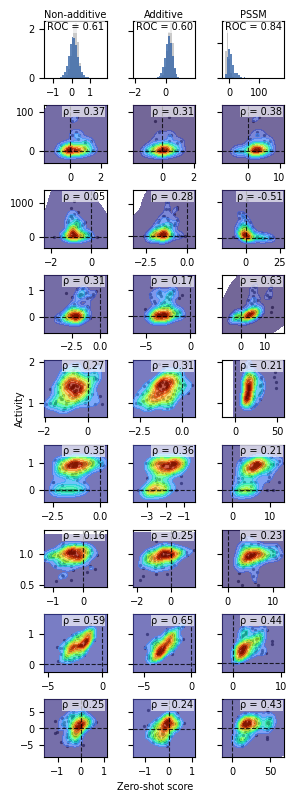

In [85]:
models = [
    "esm_8m",
    "esm_35m",
    "esm_150m",
    "esm_650m",
    "esm_3b",
    "progen2-small",
    "progen2-medium"
]
non_additive_model = "esm_150m"
additive_model = "esm_650m"
pssm_score = "avg_score"

log_activity_datasets = []

selected_score_specs = {
    "Non-additive": (
        "non-linear",
        non_additive_model,
        "normed_fitness",
    ),
    "Additive": (
        "additive",
        additive_model,
        "normed_fitness",
    ),
    f"PSSM": (
        "pssm",
        "pssm",
        pssm_score,
    ),
}

dataset_order = datasets_for_analysis

fig3, axes3 = plot_model_fitness_panels(
    plot_data,
    score_specs=selected_score_specs,
    dataset_order=["gfp", "pte", "nmt", "pard3", "gcn4", "his2", "his5", "lov", "casp"],
    roc_datasets=["gfp"],
    spearman_datasets=[
        dataset
        for dataset in dataset_order
        if dataset != "gfp"
    ],
    label_type="pct_0.5",
    figsize=(2.6, 8),
    kde=True,
    kde_cmap="turbo",
    max_np=100,
    limit_axes=["gcn4", "his2", "his5"],
    n_std=2.5,
    log_activity_datasets=log_activity_datasets,
    log_epsilon=1e-5,
    text_size=7,
    wspace=0.425,
    hspace=0.475,
)



In [11]:
export_plot("examplery_scatterplots", fig=fig3)

PosixPath('/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/zero_shot/examplery_scatterplots.svg')

PosixPath('/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/zero_shot/examplery_roc_all_models.svg')

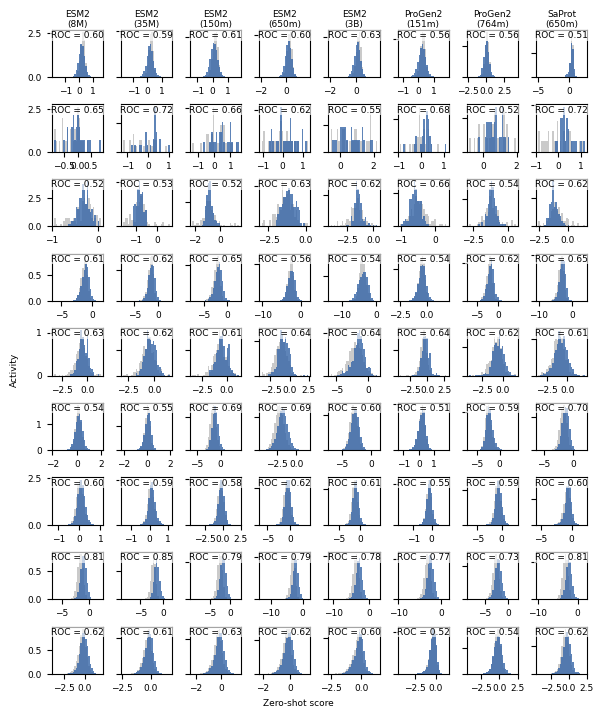

In [11]:
spearman = False

models = [
    "esm_8m",
    "esm_35m",
    "esm_150m",
    "esm_650m",
    "esm_3b",
    "progen2-small",
    "progen2-medium",
    "saprot"
]

# Choose either "additive" or "non-linear".
# for simplicity, we show spearman with addtive and roc-auc with non additive
# (just for the supp)
zs_type = "additive" if spearman else "non-linear"

selected_score_specs = {
    model_names_label_dict.get(model, model): (
        zs_type,
        model,
        "normed_fitness",
    )
    for model in models
}

if spearman:
    plot_dataset_order = [
        "pte",
        "nmt",
        "pard3",
        "gcn4",
        "his2",
        "his5",
        "lov",
        "casp",
    ]
else:
    plot_dataset_order = [
        "gfp",
        "pte",
        "nmt",
        "pard3",
        "gcn4",
        "his2",
        "his5",
        "lov",
        "casp",
    ]


fig3, axes3 = plot_model_fitness_panels(
    plot_data,
    score_specs=selected_score_specs,
    dataset_order=plot_dataset_order,
    roc_datasets=plot_dataset_order if not spearman else [],
    spearman_datasets=[] if not spearman else plot_dataset_order,
    label_type="pct_0.5",
    figsize=(5.8, 7) if not spearman else (8,  8),
    kde=True,
    kde_cmap="turbo",
    max_np=100,
    limit_axes=["gcn4", "his2", "his5"],
    n_std=3,
    log_activity_datasets=log_activity_datasets,
    log_epsilon=1e-5,
    text_size=6.5,
    wspace=0.35,
    hspace=0.575,
)

export_plot("examplery_scatterplots_all_models" if spearman else "examplery_roc_all_models", fig=fig3)
#plt.show()

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


model_names_label_dict = {
    "esm_8m": "ESM2\n(8M)",
    "esm_35m": "ESM2\n(35M)",
    "esm_150m": "ESM2\n(150M)",
    "esm_650m": "ESM2\n(650M)",
    "esm_3b": "ESM2\n(3B)",
    "progen2-small": "ProGen2\n(151M)",
    "progen2-medium": "ProGen2\n(764M)",
    "prot_bert": "ProtBERT",
    "pssm": "PSSM",
    "saprot": "SaProt\n(650m)"
}

panel_labels = {
    "correlation": r"Spearman's $\rho$",
    "roc_auc": "ROC-AUC",
}
def plot_scores(
    final_score_df,
    num_muts=None,
    label_type="pct_0.5",
    model_order=None,
    dataset_order=None,
    zs_order=None,
    color_map=None,
    color_by="dataset",
    palette="colorblind",
    panel_order=("correlation", "roc_auc"),
    model_label_map=None,
    bar_height=0.14,
    bar_edgecolor="black",
    bar_linewidth=0.6,
    show_values=True,
    value_label_mode="alternate",
    alternate_value_zs=None,
    value_text_size=6,
    value_decimals=2,
    value_pad=0.01,
    dataset_gap=0.015,
    model_gap=0.35,
    abs_correlation=False,
    invariant_auc=False,
    figsize=(8, 6),
    panel_gap=0.08,
    path=None,
):
    """Plot Spearman correlation and ROC-AUC in aligned horizontal panels."""
    if value_label_mode not in {"alternate", "both", "max"}:
        raise ValueError("value_label_mode must be 'alternate', 'both', or 'max'.")

    if alternate_value_zs is None:
        alternate_value_zs = {
            "correlation": "additive",
            "roc_auc": "non-linear",
        }

    df = final_score_df.copy()
    df = df[df["score_type"].isin(panel_order)].copy()
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = df[np.isfinite(df["value"])]

    if label_type is not None:
        correlation_rows = df["score_type"].eq("correlation")
        auc_rows = df["score_type"].eq("roc_auc")
        requested_auc = df["label_type"].eq(label_type)
        gfp_auc = df["dataset"].eq("gfp") & df["label_type"].eq("gfp_inactive_false")
        df = df[correlation_rows | (auc_rows & (requested_auc | gfp_auc))]

    # if abs_correlation:
    #     correlation_rows = df["score_type"].eq("correlation")
    #     df.loc[correlation_rows, "value"] = df.loc[correlation_rows, "value"].abs()

    #if invariant_auc:
    auc_rows = df["score_type"].eq("roc_auc") & df["value"].lt(0.5)
    df.loc[auc_rows, "value"] = 1 - df.loc[auc_rows, "value"]

    if num_muts is not None:
        num_muts = [num_muts] if np.isscalar(num_muts) else list(num_muts)
        df = df[df["num_mutations"].isin(num_muts)]

    if df.empty:
        raise ValueError("No rows remain after filtering.")

    df["zs_plot"] = df["zs"].fillna("").astype(str)

    mutation_df = (
        df.groupby(
            ["score_type", "model", "dataset", "zs_plot", "num_mutations"],
            dropna=False,
        )["value"]
        .median()
        .reset_index()
    )

    plot_df = (
        mutation_df.groupby(
            ["score_type", "model", "dataset", "zs_plot"],
            dropna=False,
        )["value"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    if model_order is None:
        model_order = list(pd.unique(plot_df["model"]))
    else:
        available_models = set(plot_df["model"])
        model_order = [model for model in model_order if model in available_models]

    if dataset_order is None:
        dataset_order = list(pd.unique(plot_df["dataset"]))
    else:
        available_datasets = set(plot_df["dataset"])
        dataset_order = [
            dataset for dataset in dataset_order if dataset in available_datasets
        ]

    if zs_order is None:
        zs_order = list(pd.unique(plot_df["zs_plot"]))
    else:
        available_zs = set(plot_df["zs_plot"])
        zs_order = [zs for zs in zs_order if zs in available_zs]

    plot_df = plot_df[
        plot_df["model"].isin(model_order)
        & plot_df["dataset"].isin(dataset_order)
        & plot_df["zs_plot"].isin(zs_order)
    ].copy()

    if plot_df.empty:
        raise ValueError("No rows remain after applying the plotting orders.")

    if color_by not in {"dataset", "model"}:
        raise ValueError("color_by must be 'dataset' or 'model'.")

    if model_label_map is None:
        model_label_map = model_names_label_dict

    categories = dataset_order if color_by == "dataset" else model_order
    resolved_colors = {} if color_map is None else dict(color_map)
    missing_colors = [
        category for category in categories if category not in resolved_colors
    ]

    if missing_colors:
        palette_colors = sns.color_palette(palette, n_colors=len(missing_colors))
        resolved_colors.update(dict(zip(missing_colors, palette_colors)))

    available_keys = {
        (row.model, row.dataset, row.zs_plot)
        for row in plot_df.itertuples(index=False)
    }

    models_with_data = [
        model
        for model in model_order
        if any(key[0] == model for key in available_keys)
    ]

    y_lookup = {}
    yticks = []
    yticklabels = []
    current_y = 0.0

    for model_index, model in enumerate(models_with_data):
        model_positions = []
        datasets_with_data = [
            dataset
            for dataset in dataset_order
            if any((model, dataset, zs) in available_keys for zs in zs_order)
        ]

        for dataset_index, dataset in enumerate(datasets_with_data):
            zs_with_data = [
                zs for zs in zs_order if (model, dataset, zs) in available_keys
            ]

            for zs in zs_with_data:
                y_lookup[(model, dataset, zs)] = current_y
                model_positions.append(current_y)
                current_y += bar_height

            if dataset_index < len(datasets_with_data) - 1:
                current_y += dataset_gap

        yticks.append(np.mean(model_positions))
        yticklabels.append(model_label_map.get(model, model))

        if model_index < len(models_with_data) - 1:
            current_y += model_gap

    fig, axes = plt.subplots(
        1,
        len(panel_order),
        figsize=figsize,
        sharey=True,
        squeeze=False,
    )
    axes = axes.ravel()
    plotted_rows = []

    for panel_index, (score_type, ax) in enumerate(zip(panel_order, axes)):
        panel = plot_df[plot_df["score_type"] == score_type].copy()

        if panel.empty:
            ax.set_visible(False)
            continue

        panel["y"] = [
            y_lookup[(row.model, row.dataset, row.zs_plot)]
            for row in panel.itertuples(index=False)
        ]

        colors = [
            resolved_colors[getattr(row, color_by)]
            for row in panel.itertuples(index=False)
        ]

        bar_baseline = 0.5 if score_type == "roc_auc" else 0.0
        bar_widths = panel["mean"] - bar_baseline
        
        ax.barh(
            panel["y"],
            bar_widths,
            left=bar_baseline,
            height=bar_height,
            color=colors,
            edgecolor=bar_edgecolor,
            linewidth=bar_linewidth,
            alpha=0.85,
            zorder=3,
        )

        has_error = panel["count"].gt(1) & np.isfinite(panel["std"])

        if has_error.any():
            ax.errorbar(
                panel.loc[has_error, "mean"],
                panel.loc[has_error, "y"],
                xerr=panel.loc[has_error, "std"],
                fmt="none",
                ecolor="black",
                elinewidth=0.8,
                capsize=2,
                zorder=4,
            )

        model_zs_df = (
            panel.groupby(["model", "zs_plot"], dropna=False)["mean"]
            .median()
            .reset_index()
        )

        overall_mean = model_zs_df["mean"].mean()
        overall_std = model_zs_df["mean"].std(ddof=1)

        if not np.isfinite(overall_std):
            overall_std = 0

        ax.axvspan(
            overall_mean - overall_std,
            overall_mean + overall_std,
            color="gray",
            alpha=0.15,
            zorder=0,
        )
        ax.axvline(
            overall_mean,
            color="gray",
            linestyle="--",
            linewidth=1,
            zorder=1,
        )
        ax.axvline(
            bar_baseline,
            color="black",
            linewidth=0.8,
            zorder=1,
        )
        error_values = panel["std"].fillna(0).to_numpy()
        lower_values = panel["mean"].to_numpy() - error_values
        xmin = np.nanmin(lower_values) - 0.02

        if score_type == "roc_auc":
            xmin = 0.5
        elif abs_correlation:
            xmin = 0

        ax.set_xlim(xmin, 1)
        ax.margins(x=0)
                
        if show_values:
            x_range = 1 - xmin
            offset = value_pad * x_range

            def add_value_label(value, y_position):
                if not np.isfinite(value):
                    return

                if value >= 0:
                    if value + offset < 1:
                        text_x = value + offset
                        horizontal_alignment = "left"
                    else:
                        text_x = value - offset
                        horizontal_alignment = "right"
                else:
                    if value - offset > xmin:
                        text_x = value - offset
                        horizontal_alignment = "right"
                    else:
                        text_x = value + offset
                        horizontal_alignment = "left"

                ax.text(
                    text_x,
                    y_position,
                    f"{value:.{value_decimals}f}",
                    ha=horizontal_alignment,
                    va="center",
                    fontsize=value_text_size,
                    clip_on=True,
                    zorder=5,
                )

            if value_label_mode == "both":
                for row in panel.itertuples(index=False):
                    add_value_label(row.mean, row.y)

            elif value_label_mode == "alternate":
                required_zs = alternate_value_zs.get(score_type)

                for row in panel.itertuples(index=False):
                    if row.zs_plot == required_zs:
                        add_value_label(row.mean, row.y)

            else:
                pair_data = panel[
                    panel["zs_plot"].isin(["additive", "non-linear"])
                ]

                for _, pair in pair_data.groupby(["model", "dataset"], sort=False):
                    pair = pair.drop_duplicates("zs_plot")

                    if set(pair["zs_plot"]) != {"additive", "non-linear"}:
                        continue

                    maximum = pair["mean"].max()
                    middle_y = pair["y"].mean()
                    add_value_label(maximum, middle_y)

        ax.set_xlabel(panel_labels.get(score_type, score_type))
        ax.set_title("")
        ax.grid(
            axis="x",
            linestyle="--",
            linewidth=0.25,
            alpha=0.7,
        )
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if panel_index == 0:
            ax.set_yticks(yticks)
            ax.set_yticklabels(yticklabels)
        else:
            ax.tick_params(axis="y", labelleft=False)

        plotted_rows.append(panel)

    axes[0].set_ylim(-bar_height, current_y)
    axes[0].set_ylabel("")

    show_legend=True
    legend_ncol=5
    legend_text_size=6

    if show_legend and "roc_auc" in panel_order:
        available_categories = set(plot_df[color_by])

        legend_handles = [
            Patch(
                facecolor=resolved_colors[category],
                edgecolor=bar_edgecolor,
                linewidth=bar_linewidth,
                alpha=0.85,
                label=category,
            )
            for category in categories
            if category in available_categories
        ]

        roc_ax = axes[list(panel_order).index("roc_auc")]

        roc_ax.legend(
            handles=legend_handles,
            loc="lower right",
            bbox_to_anchor=(0.98, 0.02),
            ncol=1,
            frameon=True,
            facecolor="white",
            edgecolor="none",
            framealpha=0.9,
            fontsize=legend_text_size,
            handlelength=1.2,
            handletextpad=0.4,
            labelspacing=0.3,
            borderaxespad=0,
        )
        fig.subplots_adjust(
            left=0.13,
            right=0.995,
            bottom=0.09,
            top=0.995,
            wspace=panel_gap,
        )
    else:
        fig.subplots_adjust(
            left=0.13,
            right=0.995,
            bottom=0.09,
            top=0.995,
            wspace=panel_gap,
        )
        
    fig.patch.set_facecolor("white")

    if path is not None:
        fig.savefig(
            path,
            bbox_inches="tight",
            pad_inches=0,
            transparent=False,
            dpi=300,
        )

    plotted_df = pd.concat(plotted_rows, ignore_index=True)

    return fig, axes, plotted_df

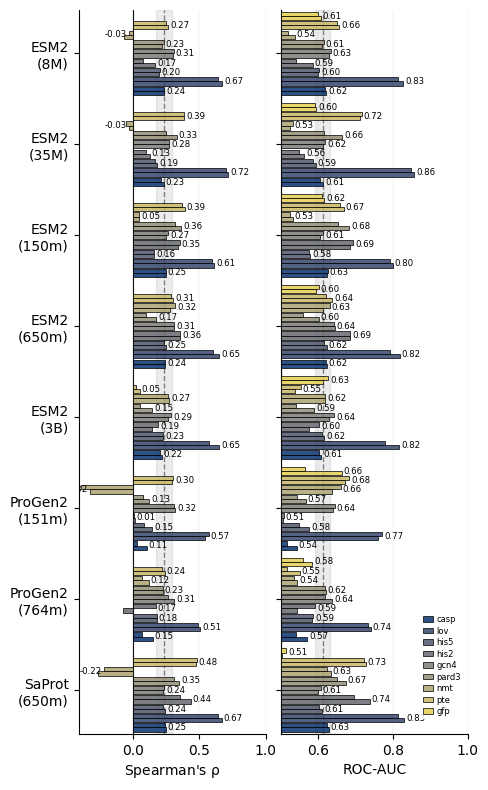

In [56]:
blue_gray_palette = sns.blend_palette(
    ["#1C1C1C", "#293A59", "#466DAE", "#6D96D4", "#B8C8E1", "#EFEFEF"],
    n_colors=9,
)


score_df = final_score_df[
    final_score_df["norm_type"].eq("normed_fitness")
]
fig, axes, plot_df = plot_scores(
    score_df,
    num_muts=-1,
    label_type="pct_0.5",
    dataset_order=["casp", "lov", "his5", "his2", "gcn4", "pard3", "nmt", "pte", "gfp"],
    model_order=[
        "saprot",
        "progen2-medium",
        "progen2-small",
        "esm_3b",
        "esm_650m",
        "esm_150m",
        "esm_35m",
        "esm_8m"
    ],
    #color_map=dataset_color_map,
    color_by="dataset",
    abs_correlation=False,
    figsize=(4.5, 8),
    dataset_gap=0.1,
    model_gap=0.75,
    bar_height=0.4,
    color_map=None,
    palette="cividis",
    bar_edgecolor="black",
    value_label_mode="max",
    bar_linewidth=0.6,
    value_text_size=6.25
)

In [15]:
export_plot("comparative_barplots_all", fig=fig)

PosixPath('/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/zero_shot/comparative_barplots_all.svg')

In [14]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import kruskal, wilcoxon


def _bh_fdr(pvalues):
    pvalues = np.asarray(pvalues, float)
    adjusted = np.full(len(pvalues), np.nan)
    valid = np.where(np.isfinite(pvalues))[0]

    if not len(valid):
        return adjusted

    order = valid[np.argsort(pvalues[valid])]
    ranked = pvalues[order] * len(order) / np.arange(1, len(order) + 1)
    adjusted[order] = np.minimum.accumulate(ranked[::-1])[::-1].clip(0, 1)

    return adjusted


def _prepare_scores(df, mutations, label_type, is_abs, invariant_auc):
    df = df[df["num_mutations"].isin(mutations)].copy()
    df = df[df["score_type"].isin(["correlation", "roc_auc"])]

    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = df[np.isfinite(df["value"])]
    df["zs_plot"] = df["zs"].fillna("").astype(str)

    if label_type is not None:
        correlation = df["score_type"].eq("correlation")
        requested_auc = df["score_type"].eq("roc_auc") & df["label_type"].eq(label_type)

        gfp_auc = (
            df["score_type"].eq("roc_auc")
            & df["dataset"].eq("gfp")
            & df["label_type"].eq("gfp_inactive_false")
        )

        df = df[correlation | requested_auc | gfp_auc]

    correlation = df["score_type"].eq("correlation")

    if is_abs:
        df.loc[correlation, "value"] = df.loc[correlation, "value"].abs()

    if invariant_auc:
        flip = df["score_type"].eq("roc_auc") & df["value"].lt(0.5)
        df.loc[flip, "value"] = 1 - df.loc[flip, "value"]

    return df

def _calculate_stats(results, methods, mutations, test, fdr):
    rows = []

    for score_type, mutation in itertools.product(["correlation", "roc_auc"], mutations):
        work = results[
            results["score_type"].eq(score_type)
            & results["num_mutations"].eq(mutation)
        ]

        models = {
            method: ", ".join(pd.unique(group["model"].astype(str)))
            for method, group in work.groupby("method")
        }

        if test == "kw":
            groups = [
                work.loc[work["method"].eq(method), "value"].dropna()
                for method in methods
            ]
            statistic = pvalue = np.nan

            if all(map(len, groups)):
                values = np.concatenate(groups)
                statistic, pvalue = (
                    (0.0, 1.0)
                    if np.allclose(values, values[0])
                    else kruskal(*groups)
                )

            rows.append({
                "score_type": score_type,
                "num_mutations": mutation,
                "test": "Kruskal-Wallis",
                "comparison": " vs ".join(methods),
                "models": models,
                "n_by_method": dict(zip(methods, map(len, groups))),
                "statistic": statistic,
                "pvalue": pvalue,
            })
            continue

        paired = work.pivot_table(index="dataset", columns="method", values="value")

        for left, right in itertools.combinations(methods, 2):
            if left not in paired or right not in paired:
                continue

            values = paired[[left, right]].dropna()
            statistic = pvalue = np.nan

            if len(values) >= 2:
                x, y = values[left].to_numpy(), values[right].to_numpy()
                statistic, pvalue = (
                    (0.0, 1.0) if np.allclose(x, y) else wilcoxon(x, y)
                )

            rows.append({
                "score_type": score_type,
                "num_mutations": mutation,
                "test": "Wilcoxon",
                "comparison": f"{left} vs {right}",
                "models": models,
                "left": left,
                "right": right,
                "left_model": models.get(left),
                "right_model": models.get(right),
                "n": len(values),
                "statistic": statistic,
                "pvalue": pvalue,
            })

    stats = pd.DataFrame(rows)
    stats["qvalue"] = np.nan

    if fdr:
        groups = stats.groupby(["score_type", "comparison"], sort=False).groups

        for indices in groups.values():
            indices = list(indices)
            stats.loc[indices, "qvalue"] = _bh_fdr(
                stats.loc[indices, "pvalue"].to_numpy()
            )

    stats["plot_pvalue"] = stats["qvalue"] if fdr else stats["pvalue"]
    stats["correction"] = (
        "BH within score type and comparison" if fdr else "none"
    )
    stats["significant"] = stats["plot_pvalue"].le(0.05)

    return stats

def plot_best_plms_by_mutation_vs_pssm(
    score_df,
    pssm_score_df=None,
    mutation_range=range(1, 9),
    best_plm_by="mutation",
    label_type="pct_0.5",
    plm_models=None,
    zs_order=("additive", "non-linear"),
    dataset_order=None,
    dataset_markers=None,
    is_abs=False,
    invariant_auc=False,
    test="wilcoxon",
    fdr=False,
    show_stats=True,
    show_ns=False,
    connect_datasets=True,
    show_dataset_legend=False,
    colors=None,
    box_width=0.09,
    box_alpha=0.25,
    point_size=5,
    line_alpha=0.45,
    text_size=7,
    legend_ncol=3,
    figsize=(14, 4.5),
    ylim=None,
    path=None,
):
    """Plot best additive/non-linear PLMs and PSSM for both score types."""
    if best_plm_by not in {"all", "mutation"}:
        raise ValueError("best_plm_by must be 'all' or 'mutation'.")

    test = {
        "kruskal": "kw",
        "kruskal-wallis": "kw",
    }.get(test.lower(), test.lower())

    if test not in {"wilcoxon", "kw"}:
        raise ValueError("test must be 'wilcoxon' or 'kw'.")

    plm = score_df[~score_df["model"].eq("pssm")].copy()
    embedded_pssm = score_df[score_df["model"].eq("pssm")]

    if pssm_score_df is None:
        pssm = embedded_pssm.copy()
    else:
        pssm = pssm_score_df.copy()

    if pssm.empty:
        raise ValueError(
            "PSSM is absent. Pass its avg_fitness rows as pssm_score_df."
        )

    if plm_models is not None:
        plm = plm[plm["model"].isin(plm_models)]

    mutations = [-1] + [
        mutation
        for mutation in mutation_range
        if mutation != -1
    ]

    plm = _prepare_scores(
        plm,
        mutations,
        label_type,
        is_abs,
        invariant_auc,
    )

    pssm = _prepare_scores(
        pssm,
        mutations,
        label_type,
        is_abs,
        invariant_auc,
    )

    plm = plm.groupby(
        [
            "score_type",
            "model",
            "dataset",
            "zs_plot",
            "num_mutations",
        ],
        as_index=False,
    )["value"].mean()

    pssm = pssm.groupby(
        [
            "score_type",
            "dataset",
            "num_mutations",
        ],
        as_index=False,
    )["value"].mean()

    if zs_order is None:
        zs_order = list(pd.unique(plm["zs_plot"]))
    else:
        zs_order = list(zs_order)

    if dataset_order is None:
        datasets = pd.concat([
            plm["dataset"],
            pssm["dataset"],
        ])
        dataset_order = list(pd.unique(datasets))

    methods = zs_order + ["PSSM"]
    selections = []
    frames = []

    for score_type, mutation, zs in itertools.product(
        ["correlation", "roc_auc"],
        mutations,
        zs_order,
    ):
        selection_mutation = -1 if best_plm_by == "all" else mutation

        candidates = plm[
            plm["score_type"].eq(score_type)
            & plm["num_mutations"].eq(selection_mutation)
            & plm["zs_plot"].eq(zs)
        ]

        scores = candidates.groupby("model")["value"].median()

        if scores.empty:
            continue

        model = scores.idxmax()

        selections.append({
            "score_type": score_type,
            "num_mutations": mutation,
            "zs": zs,
            "model": model,
            "selection_score": scores.loc[model],
        })

        selected = plm[
            plm["score_type"].eq(score_type)
            & plm["num_mutations"].eq(mutation)
            & plm["zs_plot"].eq(zs)
            & plm["model"].eq(model)
            & plm["dataset"].isin(dataset_order)
        ].copy()

        selected["method"] = zs
        frames.append(selected)

    selected_pssm = pssm[
        pssm["dataset"].isin(dataset_order)
    ].copy()

    selected_pssm["method"] = "PSSM"
    selected_pssm["model"] = "pssm"
    frames.append(selected_pssm)

    results = pd.concat(
        frames,
        ignore_index=True,
    )

    results = results[
        [
            "score_type",
            "num_mutations",
            "method",
            "model",
            "dataset",
            "value",
        ]
    ]

    selections = pd.DataFrame(selections)

    stats = _calculate_stats(
        results,
        methods,
        mutations,
        test,
        fdr,
    )

    method_gap = box_width * 0.2
    cluster_width = len(methods) * box_width + (len(methods) - 1) * method_gap

    centers = [
        -(cluster_width + 0.08) / 2,
        (cluster_width + 0.08) / 2,
    ]

    within = (
        np.arange(len(methods))
        - (len(methods) - 1) / 2
    ) * (box_width + method_gap)

    score_types = ["correlation", "roc_auc"]

    offsets = {
        (score_type, method): centers[score_index] + within[method_index]
        for score_index, score_type in enumerate(score_types)
        for method_index, method in enumerate(methods)
    }

    mutation_x = {
        mutation: index
        for index, mutation in enumerate(mutations)
    }

    color_keys = list(
        itertools.product(score_types, methods)
    )

    default_colors = [
        "#3665A7",
        "#81ACCE",
        "#BDBDBD",
        "#D55E00",
        "#E69F00",
        "#7A7A7A",
    ]

    resolved_colors = dict(
        zip(color_keys, itertools.cycle(default_colors))
    )

    if colors is not None:
        resolved_colors.update(colors)

    if dataset_markers is None:
        dataset_markers = {}

    fig, ax = plt.subplots(figsize=figsize)

    # Draw transparent boxplots first.
    for score_type, mutation, method in itertools.product(
        score_types,
        mutations,
        methods,
    ):
        values = results.loc[
            results["score_type"].eq(score_type)
            & results["num_mutations"].eq(mutation)
            & results["method"].eq(method),
            "value",
        ]

        if values.empty:
            continue

        position = (
            mutation_x[mutation]
            + offsets[(score_type, method)]
        )

        box = ax.boxplot(
            values,
            positions=[position],
            widths=box_width,
            patch_artist=True,
            showfliers=False,
            manage_ticks=False,
            medianprops={
                "color": "black",
                "linewidth": 0.8,
            },
            boxprops={
                "edgecolor": "black",
                "linewidth": 0.6,
            },
            whiskerprops={
                "color": "black",
                "linewidth": 0.6,
            },
            capprops={
                "color": "black",
                "linewidth": 0.6,
            },
        )

        box["boxes"][0].set_facecolor(
            resolved_colors[(score_type, method)]
        )
        box["boxes"][0].set_alpha(box_alpha)

    # Draw paired dataset lines and points in front.
    for (score_type, mutation, dataset), group in results.groupby(
        [
            "score_type",
            "num_mutations",
            "dataset",
        ]
    ):
        values = group.groupby("method")["value"].mean()

        present = [
            method
            for method in methods
            if method in values
        ]

        x = [
            mutation_x[mutation] + offsets[(score_type, method)]
            for method in present
        ]

        y = values.loc[present]
        marker = dataset_markers.get(dataset, "o")

        if connect_datasets and len(present) > 1:
            ax.plot(
                x,
                y,
                color="#555555",
                linewidth=0.55,
                alpha=line_alpha,
                zorder=4,
            )

        ax.scatter(
            x,
            y,
            color="#555555",
            marker=marker,
            s=point_size,
            alpha=min(1, line_alpha + 0.2),
            linewidths=0,
            zorder=5,
        )

    data_min = results["value"].min()
    data_max = results["value"].max()
    plot_range = max(1.0, data_max - data_min)
    annotation_top = data_max

    if show_stats:
        for score_type, mutation in itertools.product(
            score_types,
            mutations,
        ):
            work = stats[
                stats["score_type"].eq(score_type)
                & stats["num_mutations"].eq(mutation)
                & np.isfinite(stats["plot_pvalue"])
            ]

            if not show_ns:
                work = work[
                    work["plot_pvalue"].le(0.05)
                ]

            local = results[
                results["score_type"].eq(score_type)
                & results["num_mutations"].eq(mutation)
            ]

            height = (
                local["value"].max()
                + 0.025 * plot_range
            )

            for row in work.itertuples(index=False):
                if test == "kw":
                    left = methods[0]
                    right = methods[-1]
                else:
                    left = row.left
                    right = row.right

                x1 = (
                    mutation_x[mutation]
                    + offsets[(score_type, left)]
                )

                x2 = (
                    mutation_x[mutation]
                    + offsets[(score_type, right)]
                )

                pvalue = row.plot_pvalue
                cap = 0.008 * plot_range

                if pvalue <= 0.0001:
                    stars = "****"
                elif pvalue <= 0.001:
                    stars = "***"
                elif pvalue <= 0.01:
                    stars = "**"
                elif pvalue <= 0.05:
                    stars = "*"
                else:
                    stars = "ns"

                ax.plot(
                    [x1, x1, x2, x2],
                    [
                        height,
                        height + cap,
                        height + cap,
                        height,
                    ],
                    color="black",
                    linewidth=0.45,
                    zorder=6,
                )

                ax.text(
                    (x1 + x2) / 2,
                    height + cap,
                    stars,
                    ha="center",
                    va="bottom",
                    fontsize=max(4, text_size - 1),
                    zorder=7,
                )

                height += 0.04 * plot_range
                annotation_top = max(
                    annotation_top,
                    height + cap,
                )

    score_labels = {
        "correlation": r"Spearman $\rho$",
        "roc_auc": "ROC-AUC",
    }

    handles = [
        Patch(
            facecolor=resolved_colors[key],
            alpha=max(0.55, box_alpha),
            label=f"{score_labels[key[0]]} - {key[1]}",
        )
        for key in color_keys
    ]

    if show_dataset_legend:
        handles += [
            Line2D(
                [0],
                [0],
                color="#555555",
                marker=dataset_markers.get(dataset, "o"),
                linewidth=0.5,
                markersize=3,
                label=dataset,
            )
            for dataset in dataset_order
        ]

    fig.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=min(legend_ncol, len(handles)),
        frameon=False,
        fontsize=text_size,
    )

    ax.set_xticks(range(len(mutations)))
    ax.set_xticklabels([
        "All" if mutation == -1 else mutation
        for mutation in mutations
    ])

    ax.set_xlim(-0.5, len(mutations) - 0.5)
    ax.set_xlabel("Number of mutations", labelpad=2)
    ax.set_ylabel("Score", labelpad=2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=text_size, pad=2)

    if ylim is None:
        lower = (
            0
            if data_min >= 0
            else max(-1.05, data_min - 0.05 * plot_range)
        )

        upper = max(
            1.02,
            annotation_top + 0.03 * plot_range,
        )

        ax.set_ylim(lower, upper)
    else:
        ax.set_ylim(*ylim)

    fig.subplots_adjust(
        left=0.065,
        right=0.995,
        bottom=0.11,
        top=0.88,
    )

    if path is not None:
        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
        )

    return fig, results, selections, stats

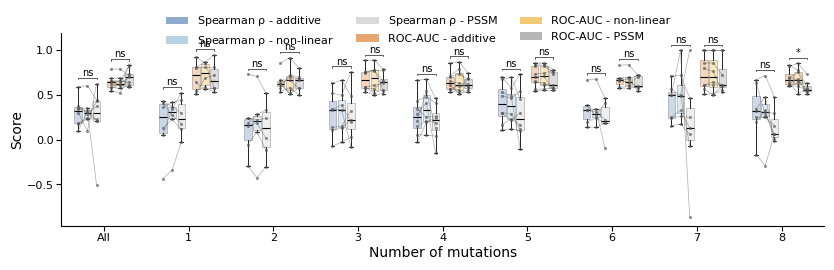

In [15]:
score_df = final_score_df[
    final_score_df["norm_type"].eq("normed_fitness")
].copy()

pssm_score_df = final_score_df[
    final_score_df["model"].eq("pssm")
    & final_score_df["norm_type"].eq("avg_score")
].copy()

fig, results, selections, stats = plot_best_plms_by_mutation_vs_pssm(
    score_df,
    pssm_score_df=pssm_score_df,
    mutation_range=range(1, 9),
    best_plm_by="mutation",
    zs_order=["additive", "non-linear"],
    label_type="pct_0.5",
    is_abs=False,
    invariant_auc=True,
    test="kw",
    show_stats=True,
    show_ns=True,
    connect_datasets=True,
    figsize=(8.2, 2.5),
    text_size=8,
    #show_dataset_legend=False
)

plt.show()

In [18]:
stats["models"][10]

{'PSSM': 'pssm', 'additive': 'esm_3b', 'non-linear': 'esm_150m'}

In [16]:
def plot_best_plms_by_mutation_vs_pssm(
    score_df,
    pssm_score_df=None,
    mutation_range=range(1, 9),
    best_plm_by="mutation",
    label_type="pct_0.5",
    plm_models=None,
    zs_order=("additive", "non-linear"),
    dataset_order=None,
    dataset_markers=None,
    is_abs=False,
    invariant_auc=True,
    test="wilcoxon",
    fdr=False,
    show_stats=True,
    show_ns=False,
    connect_datasets=True,
    show_dataset_legend=False,
    colors=None,
    box_width=0.16,
    box_alpha=0.25,
    point_size=5,
    line_alpha=0.45,
    text_size=7,
    figsize=(14, 4.5),
    panel_gap=0.12,
    ylims=None,
    path=None,
):
    """Plot Spearman and ROC-AUC in two separate panels."""
    if best_plm_by not in {"all", "mutation"}:
        raise ValueError("best_plm_by must be 'all' or 'mutation'.")

    test = {
        "kruskal": "kw",
        "kruskal-wallis": "kw",
    }.get(test.lower(), test.lower())

    if test not in {"wilcoxon", "kw"}:
        raise ValueError("test must be 'wilcoxon' or 'kw'.")

    plm = score_df[~score_df["model"].eq("pssm")].copy()
    embedded_pssm = score_df[score_df["model"].eq("pssm")]

    if pssm_score_df is None:
        pssm = embedded_pssm.copy()
    else:
        pssm = pssm_score_df.copy()

    if pssm.empty:
        raise ValueError(
            "PSSM is absent. Pass its avg_fitness rows as pssm_score_df."
        )

    if plm_models is not None:
        plm = plm[plm["model"].isin(plm_models)]

    mutations = [-1] + [
        mutation
        for mutation in mutation_range
        if mutation != -1
    ]

    plm = _prepare_scores(plm,mutations, label_type, is_abs, invariant_auc)
    pssm = _prepare_scores(pssm,mutations, label_type, is_abs, invariant_auc)

    plm = plm.groupby(["score_type", "model", "dataset", "zs_plot", "num_mutations"], as_index=False)["value"].mean()
    pssm = pssm.groupby(["score_type", "dataset", "num_mutations"], as_index=False)["value"].mean()

    if zs_order is None:
        zs_order = list(pd.unique(plm["zs_plot"]))
    else:
        zs_order = list(zs_order)

    if dataset_order is None:
        datasets = pd.concat([
            plm["dataset"],
            pssm["dataset"],
        ])
        dataset_order = list(pd.unique(datasets))
    else:
        dataset_order = list(dataset_order)

    methods = zs_order + ["PSSM"]
    selections = []
    frames = []

    for score_type, mutation, zs in itertools.product(["correlation", "roc_auc"], mutations, zs_order):
        selection_mutation = (
            -1
            if best_plm_by == "all"
            else mutation
        )

        candidates = plm[
            plm["score_type"].eq(score_type)
            & plm["num_mutations"].eq(selection_mutation)
            & plm["zs_plot"].eq(zs)
        ]

        scores = candidates.groupby("model")["value"].median()

        if scores.empty:
            continue

        model = scores.idxmax()

        selections.append({
            "score_type": score_type,
            "num_mutations": mutation,
            "zs": zs,
            "model": model,
            "selection_score": scores.loc[model],
        })

        selected = plm[
            plm["score_type"].eq(score_type)
            & plm["num_mutations"].eq(mutation)
            & plm["zs_plot"].eq(zs)
            & plm["model"].eq(model)
            & plm["dataset"].isin(dataset_order)
        ].copy()

        selected["method"] = zs
        frames.append(selected)

    selected_pssm = pssm[pssm["dataset"].isin(dataset_order)].copy()
    selected_pssm["method"] = "PSSM"
    selected_pssm["model"] = "pssm"
    frames.append(selected_pssm)

    results = pd.concat(frames, ignore_index=True)
    results = results[
        [
            "score_type",
            "num_mutations",
            "method",
            "model",
            "dataset",
            "value",
        ]
    ]

    selections = pd.DataFrame(selections)

    stats = _calculate_stats(results, methods, mutations, test, fdr)
    score_types = ["correlation", "roc_auc"]

    panel_labels = {
        "correlation": r"Spearman $\rho$",
        "roc_auc": "ROC-AUC",
    }

    mutation_x = {mutation: index for index, mutation in enumerate(mutations)}

    method_offsets = (np.arange(len(methods)) - (len(methods) - 1) / 2) * box_width * 1.25
    method_offsets = dict(zip(methods, method_offsets))

    default_colors = {
        "additive": "#3665A7",
        "non-linear": "#81ACCE",
        "PSSM": "#BDBDBD",
    }

    resolved_colors = default_colors | (
        {} if colors is None else colors
    )

    if dataset_markers is None:
        dataset_markers = {}

    fig, axes = plt.subplots(
        1,
        2,
        figsize=figsize,
    )

    for ax, score_type in zip(axes, score_types):
        panel = results[results["score_type"] == score_type]
   
        # Draw transparent boxplots first.
        for mutation, method in itertools.product(mutations, methods):
 
            values = panel.loc[
                panel["num_mutations"].eq(mutation)
                & panel["method"].eq(method),
                "value",
            ]

            if values.empty:
                continue

            position = (mutation_x[mutation]+ method_offsets[method])

            box = ax.boxplot(
                values,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                showfliers=False,
                manage_ticks=False,
                medianprops={
                    "color": "black",
                    "linewidth": 0.8,
                },
                boxprops={
                    "edgecolor": "black",
                    "linewidth": 0.6,
                },
                whiskerprops={
                    "color": "black",
                    "linewidth": 0.6,
                },
                capprops={
                    "color": "black",
                    "linewidth": 0.6,
                },
            )

            box["boxes"][0].set_facecolor(resolved_colors[method])
            box["boxes"][0].set_alpha(box_alpha)

        # Draw paired dataset lines and points in front.
        for (mutation, dataset), group in panel.groupby(["num_mutations","dataset",]):
            values = group.groupby("method")["value"].mean()

            present = [method for method in methods if method in values]
       

            x = [
                mutation_x[mutation] + method_offsets[method]
                for method in present
            ]

            y = values.loc[present]
            marker = dataset_markers.get(dataset, "o")

            if connect_datasets and len(present) > 1:
                ax.plot(
                    x,
                    y,
                    color="#555555",
                    linewidth=0.55,
                    alpha=line_alpha,
                    zorder=4,
                )

            ax.scatter(
                x,
                y,
                color="#555555",
                marker=marker,
                s=point_size,
                alpha=min(1, line_alpha + 0.2),
                linewidths=0,
                zorder=5,
            )

        data_min = panel["value"].min()
        data_max = panel["value"].max()
        plot_range = max(0.1, data_max - data_min)
        annotation_top = data_max

        if show_stats:
            panel_stats = stats[
                stats["score_type"].eq(score_type)
                & np.isfinite(stats["plot_pvalue"])
            ]

            if not show_ns:
                panel_stats = panel_stats[
                    panel_stats["plot_pvalue"].le(0.05)
                ]

            for mutation in mutations:
                work = panel_stats[
                    panel_stats["num_mutations"].eq(mutation)
                ]

                local = panel[
                    panel["num_mutations"].eq(mutation)
                ]

                if local.empty:
                    continue

                height = (
                    local["value"].max()
                    + 0.05 * plot_range
                )

                for row in work.itertuples(index=False):
                    if test == "kw":
                        left = methods[0]
                        right = methods[-1]
                    else:
                        left = row.left
                        right = row.right

                    x1 = (
                        mutation_x[mutation]
                        + method_offsets[left]
                    )

                    x2 = (
                        mutation_x[mutation]
                        + method_offsets[right]
                    )

                    pvalue = row.plot_pvalue
                    cap = 0.015 * plot_range

                    if pvalue <= 0.0001:
                        stars = "****"
                    elif pvalue <= 0.001:
                        stars = "***"
                    elif pvalue <= 0.01:
                        stars = "**"
                    elif pvalue <= 0.05:
                        stars = "*"
                    else:
                        stars = "ns"

                    ax.plot(
                        [x1, x1, x2, x2],
                        [
                            height,
                            height + cap,
                            height + cap,
                            height,
                        ],
                        color="black",
                        linewidth=0.45,
                        zorder=6,
                    )

                    ax.text(
                        (x1 + x2) / 2,
                        height + cap,
                        stars,
                        ha="center",
                        va="bottom",
                        fontsize=max(4, text_size - 1),
                        zorder=7,
                    )

                    height += 0.07 * plot_range
                    annotation_top = max(
                        annotation_top,
                        height + cap,
                    )

        ax.set_xticks(range(len(mutations)))

        ax.set_xticklabels([
            "All" if mutation == -1 else mutation
            for mutation in mutations
        ])

        ax.set_xlim(
            -0.5,
            len(mutations) - 0.5,
        )

        ax.set_xlabel(
            "Number of mutations",
            labelpad=2,
        )

        ax.set_ylabel(
            "Score",
            labelpad=2,
        )

        ax.set_title(
            panel_labels[score_type],
            fontsize=text_size + 1,
        )

        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=text_size, pad=2)

        if ylims is not None and score_type in ylims:
            ax.set_ylim(*ylims[score_type])
        else:
            lower = data_min - 0.08 * plot_range

            if score_type == "roc_auc":
                lower = max(0, lower)
            else:
                lower = min(0, lower)

            upper = (
                annotation_top
                + 0.08 * plot_range
            )

            ax.set_ylim(lower, upper)

    handles = [
        Patch(
            facecolor=resolved_colors[method],
            alpha=max(0.55, box_alpha),
            label=method,
        )
        for method in methods
    ]

    if show_dataset_legend:
        handles += [
            Line2D(
                [0],
                [0],
                color="#555555",
                marker=dataset_markers.get(dataset, "o"),
                linewidth=0.5,
                markersize=3,
                label=dataset,
            )
            for dataset in dataset_order
        ]

    fig.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=min(3, len(handles)),
        frameon=False,
        fontsize=text_size,
    )

    fig.subplots_adjust(
        left=0.06,
        right=0.995,
        bottom=0.12,
        top=0.88,
        wspace=panel_gap,
    )

    if path is not None:
        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
        )

    return fig, results, selections, stats

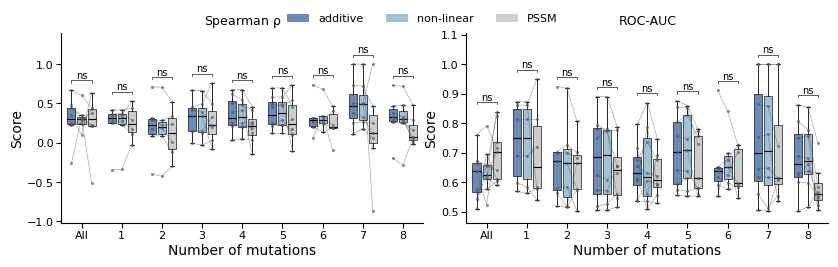

In [57]:
score_df = final_score_df[
    final_score_df["norm_type"].eq("normed_fitness")
].copy()

pssm_score_df = final_score_df[
    final_score_df["model"].eq("pssm")
    & final_score_df["norm_type"].eq("avg_score")
].copy()

fig, results, selections, stats = plot_best_plms_by_mutation_vs_pssm(
    score_df,
    pssm_score_df=pssm_score_df,
    mutation_range=range(1, 9),
    best_plm_by="mutation",
    zs_order=["additive", "non-linear"],
    label_type="pct_0.5",
    is_abs=False,
    invariant_auc=True,
    test="kw",
    show_stats=True,
    show_ns=True,
    connect_datasets=True,
    figsize=(8.2, 2.5),
    text_size=8,
    fdr=True,
    box_width=0.2,
    box_alpha=0.75,
    #show_dataset_legend=False
)

plt.show()

In [84]:
print(stats["models"][15])

{'PSSM': 'pssm', 'additive': 'esm_35m', 'non-linear': 'esm_150m'}


In [44]:
export_plot("comp_boxplots", fig=fig)

PosixPath('/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/zero_shot/comp_boxplots.svg')

In [21]:
final_score_df["model"].unique()

array(['esm_8m', 'esm_35m', 'esm_150m', 'esm_650m', 'esm_3b',
       'progen2-medium', 'progen2-small', 'saprot', 'pssm'], dtype=object)

In [22]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal, wilcoxon


def plot_best_plms_by_mutation_vs_pssm_bars(
    score_df,
    pssm_score_df=None,
    mutation_range=range(1, 9),
    best_plm_by="mutation",
    label_type="pct_0.5",
    plm_models=None,
    zs_order=("additive", "non-linear"),
    dataset_order=None,
    is_abs=False,
    invariant_auc=False,
    test="wilcoxon",
    fdr=False,
    show_stats=True,
    show_ns=False,
    show_points=False,
    errorbar="sem",
    colors=None,
    bar_alpha=0.8,
    text_size=7,
    figsize=(10, 3.5),
    ylim=None,
    path=None,
):
    """
    Plot the best additive/non-linear PLMs and PSSM as two barplot panels.

    Bars show the mean across datasets. Error bars are SEM, SD, or omitted.
    The best PLM is selected by median score across datasets, separately for
    each score type, mutational order, and zero-shot method.

    Returns
    -------
    fig, results, selections, stats
    """
    if best_plm_by not in {"all", "mutation"}:
        raise ValueError("best_plm_by must be 'all' or 'mutation'.")
    if errorbar not in {"sem", "sd", None}:
        raise ValueError("errorbar must be 'sem', 'sd', or None.")

    test = {"kruskal": "kw", "kruskal-wallis": "kw"}.get(test.lower(), test.lower())
    if test not in {"wilcoxon", "kw"}:
        raise ValueError("test must be 'wilcoxon' or 'kw'.")

    mutations = [-1] + [m for m in mutation_range if m != -1]
    score_types = ["correlation", "roc_auc"]
    zs_order = list(zs_order)
    methods = zs_order + ["PSSM"]

    def prepare(df):
        df = df[
            df["num_mutations"].isin(mutations)
            & df["score_type"].isin(score_types)
        ].copy()

        df["value"] = pd.to_numeric(df["value"], errors="coerce")
        df = df[np.isfinite(df["value"])]
        df["zs_plot"] = df["zs"].fillna("").astype(str) if "zs" in df else ""

        if label_type is not None:
            corr = df["score_type"].eq("correlation")
            auc = (
                df["score_type"].eq("roc_auc")
                & df["label_type"].eq(label_type)
            )
            gfp = (
                df["score_type"].eq("roc_auc")
                & df["dataset"].eq("gfp")
                & df["label_type"].eq("gfp_inactive_false")
            )
            df = df[corr | auc | gfp]

        corr = df["score_type"].eq("correlation")

        if is_abs:
            df.loc[corr, "value"] = df.loc[corr, "value"].abs()

        if invariant_auc:
            flip = df["score_type"].eq("roc_auc") & df["value"].lt(0.5)
            df.loc[flip, "value"] = 1 - df.loc[flip, "value"]

        return df

    plm = prepare(score_df[~score_df["model"].eq("pssm")])

    pssm_source = (
        score_df[score_df["model"].eq("pssm")]
        if pssm_score_df is None
        else pssm_score_df
    )
    pssm = prepare(pssm_source)

    if pssm.empty:
        raise ValueError("PSSM is absent. Pass its rows as pssm_score_df.")

    if plm_models is not None:
        plm = plm[plm["model"].isin(plm_models)]

    plm = plm.groupby(["score_type", "model", "dataset", "zs_plot", "num_mutations"],as_index=False,)["value"].mean()
    pssm = pssm.groupby(["score_type", "dataset", "num_mutations"],as_index=False,)["value"].mean()

    if dataset_order is None:
        dataset_order = pd.unique(
            pd.concat([plm["dataset"], pssm["dataset"]])
        ).tolist()
    else:
        dataset_order = list(dataset_order)

    selections = []
    selected = []

    for score_type, mutation, zs in itertools.product(
        score_types,
        mutations,
        zs_order,
    ):
        selection_mutation = -1 if best_plm_by == "all" else mutation

        candidates = plm[
            plm["score_type"].eq(score_type)
            & plm["num_mutations"].eq(selection_mutation)
            & plm["zs_plot"].eq(zs)
        ]

        model_scores = candidates.groupby("model")["value"].median()

        if model_scores.empty:
            continue

        model = model_scores.idxmax()

        selections.append({
            "score_type": score_type,
            "num_mutations": mutation,
            "zs": zs,
            "model": model,
            "selection_score": model_scores[model],
        })

        rows = plm[
            plm["score_type"].eq(score_type)
            & plm["num_mutations"].eq(mutation)
            & plm["zs_plot"].eq(zs)
            & plm["model"].eq(model)
            & plm["dataset"].isin(dataset_order)
        ].copy()

        rows["method"] = zs
        selected.append(rows)

    pssm = pssm[pssm["dataset"].isin(dataset_order)].copy()
    pssm["method"] = "PSSM"
    pssm["model"] = "pssm"
    selected.append(pssm)

    results = pd.concat(selected, ignore_index=True)[
        [
            "score_type",
            "num_mutations",
            "method",
            "model",
            "dataset",
            "value",
        ]
    ]
    selections = pd.DataFrame(selections)

    # Statistics
    stats_rows = []

    for score_type, mutation in itertools.product(score_types, mutations):
        work = results[
            results["score_type"].eq(score_type)
            & results["num_mutations"].eq(mutation)
        ]

        model_ids = {
            method: ", ".join(pd.unique(group["model"].astype(str)))
            for method, group in work.groupby("method")
        }

        if test == "kw":
            groups = [
                work.loc[work["method"].eq(method), "value"].dropna()
                for method in methods
            ]

            statistic = np.nan
            pvalue = np.nan

            if all(len(group) for group in groups):
                values = np.concatenate(groups)

                if np.allclose(values, values[0]):
                    statistic, pvalue = 0.0, 1.0
                else:
                    statistic, pvalue = kruskal(*groups)

            stats_rows.append({
                "score_type": score_type,
                "num_mutations": mutation,
                "test": "Kruskal-Wallis",
                "comparison": " vs ".join(methods),
                "models": model_ids,
                "n_by_method": dict(zip(methods, map(len, groups))),
                "statistic": statistic,
                "pvalue": pvalue,
            })

        else:
            paired = work.pivot_table(
                index="dataset",
                columns="method",
                values="value",
            )

            for left, right in itertools.combinations(methods, 2):
                if left not in paired or right not in paired:
                    continue

                values = paired[[left, right]].dropna()
                statistic = np.nan
                pvalue = np.nan

                if len(values) >= 2:
                    x = values[left].to_numpy()
                    y = values[right].to_numpy()

                    if np.allclose(x, y):
                        statistic, pvalue = 0.0, 1.0
                    else:
                        statistic, pvalue = wilcoxon(x, y)

                stats_rows.append({
                    "score_type": score_type,
                    "num_mutations": mutation,
                    "test": "Wilcoxon",
                    "comparison": f"{left} vs {right}",
                    "models": model_ids,
                    "left": left,
                    "right": right,
                    "left_model": model_ids.get(left),
                    "right_model": model_ids.get(right),
                    "n": len(values),
                    "statistic": statistic,
                    "pvalue": pvalue,
                })

    stats = pd.DataFrame(stats_rows)
    stats["qvalue"] = np.nan

    if fdr and len(stats):
        pvalues = stats["pvalue"].to_numpy(float)
        valid = np.flatnonzero(np.isfinite(pvalues))
        order = valid[np.argsort(pvalues[valid])]

        ranked = (
            pvalues[order]
            * len(order)
            / np.arange(1, len(order) + 1)
        )

        stats.loc[order, "qvalue"] = (
            np.minimum.accumulate(ranked[::-1])[::-1].clip(0, 1)
        )

    stats["plot_pvalue"] = (
        stats["qvalue"] if fdr else stats["pvalue"]
    )
    stats["correction"] = (
        "Benjamini-Hochberg" if fdr else "none"
    )
    stats["significant"] = stats["plot_pvalue"].le(0.05)

    # Plotting
    resolved_colors = dict(
        zip(methods, ["#3665A7", "#81ACCE", "#BDBDBD"])
    )

    if colors is not None:
        resolved_colors.update(colors)

    x = np.arange(len(mutations))
    width = 0.8 / len(methods)
    offsets = (
        np.arange(len(methods)) - (len(methods) - 1) / 2
    ) * width

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    panel_titles = [r"Spearman $\rho$", "ROC-AUC"]

    for ax, score_type, title in zip(
        axes,
        score_types,
        panel_titles,
    ):
        panel = results[results["score_type"].eq(score_type)]

        summary = panel.groupby(
            ["num_mutations", "method"]
        )["value"].agg(
            mean="mean",
            sd="std",
            n="count",
        )

        panel_top = panel["value"].max()
        panel_bottom = panel["value"].min()
        panel_range = max(panel_top - panel_bottom, 0.1)

        for method_index, method in enumerate(methods):
            means = []
            errors = []

            for mutation in mutations:
                key = (mutation, method)

                if key not in summary.index:
                    means.append(np.nan)
                    errors.append(0)
                    continue

                row = summary.loc[key]
                means.append(row["mean"])

                if errorbar is None:
                    errors.append(0)
                elif errorbar == "sem":
                    errors.append(row["sd"] / np.sqrt(row["n"]))
                else:
                    errors.append(row["sd"])

            positions = x + offsets[method_index]

            ax.bar(
                positions,
                means,
                width=width,             # Bars now touch
                yerr=errors if errorbar else None,
                capsize=2,
                color=resolved_colors[method],
                alpha=bar_alpha,
                edgecolor="none",        # No outline
                linewidth=0,
                error_kw={"elinewidth": 0.6, "capthick": 0.6},
                label=method,
                zorder=2,
            )

            if show_points:
                for mutation_index, mutation in enumerate(mutations):
                    values = panel.loc[
                        panel["num_mutations"].eq(mutation)
                        & panel["method"].eq(method),
                        "value",
                    ]

                    ax.scatter(
                        np.full(
                            len(values),
                            positions[mutation_index],
                        ),
                        values,
                        s=6,
                        facecolor="white",
                        edgecolor="black",
                        linewidth=0.35,
                        zorder=3,
                    )

        annotation_top = panel_top

        if show_stats:
            for mutation_index, mutation in enumerate(mutations):
                rows = stats[
                    stats["score_type"].eq(score_type)
                    & stats["num_mutations"].eq(mutation)
                    & np.isfinite(stats["plot_pvalue"])
                ]

                if not show_ns:
                    rows = rows[
                        rows["plot_pvalue"].le(0.05)
                    ]

                height = panel.loc[
                    panel["num_mutations"].eq(mutation),
                    "value",
                ].max()

                height += 0.05 * panel_range

                for row in rows.itertuples(index=False):
                    if test == "kw":
                        left = methods[0]
                        right = methods[-1]
                    else:
                        left = row.left
                        right = row.right

                    x1 = (
                        mutation_index
                        + offsets[methods.index(left)]
                    )
                    x2 = (
                        mutation_index
                        + offsets[methods.index(right)]
                    )

                    pvalue = row.plot_pvalue

                    if pvalue <= 1e-4:
                        stars = "****"
                    elif pvalue <= 1e-3:
                        stars = "***"
                    elif pvalue <= 1e-2:
                        stars = "**"
                    elif pvalue <= 0.05:
                        stars = "*"
                    else:
                        stars = "ns"

                    cap = 0.012 * panel_range

                    ax.plot(
                        [x1, x1, x2, x2],
                        [
                            height,
                            height + cap,
                            height + cap,
                            height,
                        ],
                        color="black",
                        linewidth=0.5,
                        zorder=4,
                    )

                    ax.text(
                        (x1 + x2) / 2,
                        height + cap,
                        stars,
                        ha="center",
                        va="bottom",
                        fontsize=max(4, text_size - 1),
                    )

                    height += 0.075 * panel_range
                    annotation_top = max(
                        annotation_top,
                        height,
                    )

        ax.set_title(
            title,
            fontsize=text_size + 1,
        )

        ax.set_xticks(
            x,
            [
                "All" if mutation == -1 else mutation
                for mutation in mutations
            ],
        )

        ax.set_xlabel(
            "Number of mutations",
            fontsize=text_size,
        )

        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=text_size, pad=2)

        ax.grid(
            axis="y",
            color="#E8E8E8",
            linewidth=0.5,
            zorder=0,
        )

        if ylim is not None:
            panel_ylim = (
                ylim.get(score_type)
                if isinstance(ylim, dict)
                else ylim
            )
            ax.set_ylim(*panel_ylim)

        else:
            lower = (
                0
                if panel_bottom >= 0
                else panel_bottom - 0.05 * panel_range
            )

            ax.set_ylim(
                lower,
                annotation_top + 0.08 * panel_range,
            )

    axes[0].set_ylabel(
        "Score",
        fontsize=text_size,
    )

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=len(methods),
        frameon=False,
        fontsize=text_size,
        bbox_to_anchor=(0.5, 1.0),
    )

    fig.subplots_adjust(
        left=0.07,
        right=0.995,
        bottom=0.16,
        top=0.84,
        wspace=0.22,
    )

    if path is not None:
        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
        )

    return fig, results, selections, stats

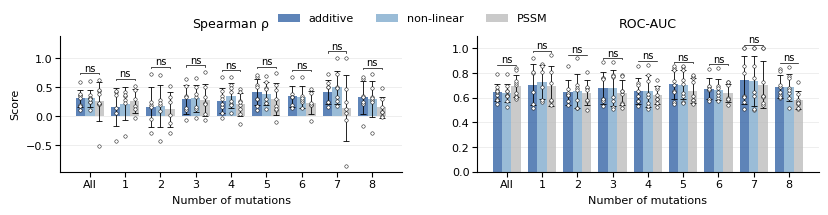

In [23]:
score_df = final_score_df[
    final_score_df["norm_type"].eq("normed_fitness")
].copy()

pssm_score_df = final_score_df[
    final_score_df["model"].eq("pssm")
    & final_score_df["norm_type"].eq("avg_score")
].copy()


fig, results, selections, stats = (
    plot_best_plms_by_mutation_vs_pssm_bars(
        score_df=score_df,
        pssm_score_df=pssm_score_df,
        mutation_range=range(1, 9),
        test="kw",
        show_ns=True,
        fdr=True,
        invariant_auc=True,
        show_points=True,
        figsize=(8.2, 2),
        text_size=8,
        errorbar="sd",
        best_plm_by="mutation"
    )
)

In [24]:
stats["models"][12]

{'PSSM': 'pssm', 'additive': 'saprot', 'non-linear': 'saprot'}

In [25]:
stats

,score_type,num_mutations,test,comparison,models,n_by_method,statistic,pvalue,qvalue,plot_pvalue,correction,significant
0,correlation,-1,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'esm_150m', 'non-...","{'additive': 8, 'non-linear': 8, 'PSSM': 8}",0.105000,0.948854,0.974360,0.974360,Benjamini-Hochberg,False
1,correlation,1,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'esm_3b', 'non-li...","{'additive': 6, 'non-linear': 6, 'PSSM': 6}",0.152047,0.926795,0.974360,0.974360,Benjamini-Hochberg,False
2,correlation,2,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'esm_35m', 'non-l...","{'additive': 6, 'non-linear': 6, 'PSSM': 6}",0.081871,0.959891,0.974360,0.974360,Benjamini-Hochberg,False
3,correlation,3,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'saprot', 'non-li...","{'additive': 7, 'non-linear': 7, 'PSSM': 7}",0.185529,0.911408,0.974360,0.974360,Benjamini-Hochberg,False
4,correlation,4,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'esm_150m', 'non-...","{'additive': 8, 'non-linear': 8, 'PSSM': 8}",1.820000,0.402524,0.974360,0.974360,Benjamini-Hochberg,False
5,correlation,5,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'saprot', 'non-li...","{'additive': 8, 'non-linear': 8, 'PSSM': 8}",1.005000,0.605016,0.974360,0.974360,Benjamini-Hochberg,False
6,correlation,6,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'esm_150m', 'non-...","{'additive': 6, 'non-linear': 6, 'PSSM': 6}",0.736842,0.691826,0.974360,0.974360,Benjamini-Hochberg,False
7,correlation,7,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'saprot', 'non-li...","{'additive': 7, 'non-linear': 7, 'PSSM': 7}",3.798976,0.149645,0.974360,0.974360,Benjamini-Hochberg,False
8,correlation,8,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'esm_650m', 'non-...","{'additive': 7, 'non-linear': 7, 'PSSM': 7}",2.946197,0.229214,0.974360,0.974360,Benjamini-Hochberg,False
9,roc_auc,-1,Kruskal-Wallis,additive vs non-linear vs PSSM,"{'PSSM': 'pssm', 'additive': 'esm_150m', 'non-...","{'additive': 9, 'non-linear': 9, 'PSSM': 9}",1.936508,0.379746,0.974360,0.974360,Benjamini-Hochberg,False


In [26]:
# def plot_model_fitness_panels(
#     normed_fitness,
#     activity,
#     act_col="Activity",
#     limit_axes=True,
#     n_std=1.5,
#     ncols=None,
#     figsize_per_panel=(1.5, 1.5),
#     kde=True,
#     max_np=10000,
#     save_path=None,
# ):
#     """
#     Plot normalized fitness vs activity for every column in normed_fitness.

#     Parameters
#     ----------
#     normed_fitness : pd.DataFrame
#         Each column corresponds to a model.

#     activity : array-like
#         Activity / target vector, same length as normed_fitness.

#     act_col : str
#         Label for the y-axis.

#     limit_axes : bool
#         If True, restrict both axes to mean +/- n_std * std.
#         Spearman correlation is still calculated using ALL data.

#     n_std : float
#         Number of standard deviations used for axis limits.

#     ncols : int or None
#         Number of subplot columns.
#         If None, all models are plotted in a single row.

#     figsize_per_panel : tuple
#         Size of each subplot.

#     kde : bool
#         Whether to draw the KDE layer.

#     max_np : int
#         Maximum number of datapoints used for plotting.
#         All datapoints are still used for Spearman correlation.

#     save_path : str or None
#         If provided, save the figure to this path.
#         If None, figure is not saved.
#     """

#     activity = np.asarray(activity)
#     n_datapoints = normed_fitness.shape[0]

#     if n_datapoints > max_np:
#         plot_indices = np.random.choice(
#             n_datapoints,
#             size=max_np,
#             replace=False
#         )
#     else:
#         plot_indices = np.arange(n_datapoints)


#     n_models = normed_fitness.shape[1]

    
#     if ncols is None:
#         ncols = n_models

#     ncols = min(ncols, n_models)
#     nrows = int(np.ceil(n_models / ncols))

#     fig, axes = plt.subplots(
#         nrows=nrows,
#         ncols=ncols,
#         figsize=(
#             figsize_per_panel[0] * ncols,
#             figsize_per_panel[1] * nrows
#         ),
#         squeeze=False,
#     )

#     axes = axes.flatten()


#     if limit_axes:

#         y_mean = np.nanmean(activity)
#         y_std = np.nanstd(activity)

#         y_lim = (
#             y_mean - n_std * y_std,
#             y_mean + n_std * y_std,
#         )


#     for i, model_name in enumerate(normed_fitness.columns):
#         ax = axes[i]
#         x = normed_fitness.iloc[:,i].to_numpy()
#         y = activity

#         valid = np.isfinite(x) & np.isfinite(y)

#         x_valid = x[valid]
#         y_valid = y[valid]

#         # Spearman on ALL valid datapoints
#         rho, _ = spearmanr(
#             x_valid,
#             y_valid
#         )

#         full_indices = np.arange(len(x))
#         valid_indices = full_indices[valid]

#         indices_to_plot = np.intersect1d(
#             plot_indices,
#             valid_indices,
#             assume_unique=False
#         )

#         x_plot = x[indices_to_plot]
#         y_plot = y[indices_to_plot]

#         plot_df = pd.DataFrame({
#             "Fitness": x_plot,
#             "Activity": y_plot,
#         })


#         ax.scatter(
#             plot_df["Fitness"],
#             plot_df["Activity"],
#             color="k",
#             s=10,
#             alpha=0.25,
#             edgecolor="white",
#             linewidth=0.2,
#             zorder=1,
#         )

#         if kde and len(plot_df) > 0:
#             sns.kdeplot(
#                 data=plot_df,
#                 x="Fitness",
#                 y="Activity",
#                 fill=True,
#                 cmap="Spectral_r",
#                 levels=20,
#                 thresh=0,
#                 alpha=0.5,
#                 bw_adjust=1,
#                 cbar=False,
#                 ax=ax,
#                 zorder=3,
#             )

#         ax.axhline(
#             y=0,
#             color="black",
#             linestyle="--",
#             linewidth=0.8,
#             alpha=0.8,
#             zorder=5,
#         )

#         ax.axvline(
#             x=0,
#             color="black",
#             linestyle="--",
#             linewidth=0.8,
#             alpha=0.8,
#             zorder=5,
#         )


#         ax.set_title(
#             f"{model_name}\nSpearman ρ = {rho:.2f}",
#             fontsize=9,
#         )

#         ax.set_xlabel("Normalized fitness")
#         ax.set_ylabel(act_col)


#         if limit_axes:

#             x_mean = np.nanmean(x_valid)
#             x_std = np.nanstd(x_valid)

#             ax.set_xlim(
#                 x_mean - n_std * x_std,
#                 x_mean + n_std * x_std,
#             )

#             ax.set_ylim(y_lim)


#     for j in range(n_models, len(axes)):
#         fig.delaxes(axes[j])


#     plt.tight_layout()


#     if save_path is not None:

#         fig.savefig(
#             save_path,
#             dpi=300,
#             bbox_inches="tight",
#         )


#     plt.show()

In [27]:
# # Use the provided color map
# color_map = {
#     "esm_8m": "#002b87",
#     "esm_35m": "#f0b800",
#     "esm_150m": "#008230",    
#     "esm_650m": "#bd0000",
#     "esm_3b": "#00cfeb",
#     "progen2-small": "#ffa500",
#     "progen2-medium": "#a603a0",
#     "prot_bert": "#3d546b"
# }

# model_names_label_dict = {
#     "esm_35m": "ESM2\n(35M)",
#     "esm_8m": "ESM2\n(8M)",
#     "esm_3b": "ESM2\n(3B)",
#     "esm_150m": "ESM2\n(150m)",
#     "esm_650m": "ESM2\n(650m)",
#     "progen2-small": "ProGen2\n(151m)",
#     "progen2-medium": "ProGen2\n(764m)"    
# }

In [28]:
# import numpy as np
# import pandas as pd

# from scipy.stats import spearmanr
# from sklearn.metrics import roc_auc_score


# def build_final_score_df(
#     datasets,
#     datasets_for_analysis,
#     num_muts_column_name,
#     positions,
#     percentiles=(0.25, 0.5, 0.75),
# ):
#     records = []

#     def add_scores(
#         dataset,
#         model,
#         predictions,
#         target,
#         nmuts,
#         score_type,
#         norm_type,
#         zs,
#         label_type=None,
#     ):
#         predictions = np.asarray(predictions, dtype=float)
#         target = np.asarray(target)
#         nmuts = np.asarray(nmuts)

#         # Catch label contamination at the point of creation.
#         if score_type == "roc_auc":
#             if dataset == "gfp":
#                 assert label_type == "gfp_inactive_false", (
#                     f"Bad GFP label: {label_type}"
#                 )
#             else:
#                 assert label_type != "gfp_inactive_false", (
#                     f"GFP label leaked into {dataset}"
#                 )
#                 assert label_type in {
#                     f"pct_{p}" for p in percentiles
#                 }, (
#                     f"Unexpected label for {dataset}: {label_type}"
#                 )
#         else:
#             assert label_type is None

#         mut_values = nmuts[~pd.isna(nmuts)]
#         mut_values = sorted(v for v in np.unique(mut_values) if v != 0)

#         groups = [-1] + mut_values

#         for num_mut in groups:
#             if num_mut == -1:
#                 mask = np.ones(len(predictions), dtype=bool)
#             else:
#                 mask = nmuts == num_mut

#             mask &= ~pd.isna(predictions)
#             mask &= ~pd.isna(target)

#             if mask.sum() < 2:
#                 continue

#             y = target[mask]
#             pred = predictions[mask]

#             if score_type == "roc_auc":
#                 if len(np.unique(y)) != 2:
#                     continue
#                 value = roc_auc_score(y, pred)
#             else:
#                 value = spearmanr(pred, y)[0]

#             if not np.isfinite(value):
#                 continue

#             row = {
#                 "dataset": dataset,
#                 "model": model,
#                 "num_mutations": num_mut,
#                 "value": value,
#                 "score_type": score_type,
#                 "fitness_type": norm_type,
#                 "norm_type": norm_type,
#                 "zs": zs,
#                 "label_type": label_type,
#             }

#             # Final guard immediately before appending.
#             if dataset != "gfp":
#                 assert row["label_type"] != "gfp_inactive_false"

#             records.append(row)

#     selected = {
#         name: ds
#         for name, ds in datasets.items()
#         if name in datasets_for_analysis
#     }


#     for ds_name, ds in selected.items():
#         print(f"Processing {ds_name}")

#         dfs_within_ds = []
#         df = pd.read_csv(ds["path"])
#         act_col = ds["activity_col"]
#         nmuts_col = num_muts_column_name[ds_name]
#         nmuts = df[nmuts_col].to_numpy()

#         results_path = f"./notebooks/{ds_name}/fitness_results/"

#         # ============================================================
#         # PLM SCORES
#         # ============================================================

#         for prefix, zs in [("", "additive"), ("pll", "non-linear")]:
#             file_prefix = f"{prefix}_" if prefix else ""

#             normed_fitness = pd.read_csv(
#                 results_path + f"{file_prefix}normed_fitness_all.csv"
#             )

#             raw_fitness = pd.read_csv(
#                 results_path + f"{file_prefix}fitness_all.csv"
#             )

#             # For PLL, ProGen should use left-to-right scores.
#             if prefix == "pll":
#                 l2r_normed = pd.read_csv(
#                     results_path + "l2r_normed_fitness_all.csv"
#                 )

#                 l2r_raw = pd.read_csv(
#                     results_path + "l2r_fitness_all.csv"
#                 )

#                 for model in ["progen2-small", "progen2-medium"]:
#                     l2r_col = f"{model}_left_to_right"

#                     if l2r_col in l2r_normed.columns:
#                         normed_fitness[model] = l2r_normed[l2r_col]

#                     if l2r_col in l2r_raw.columns:
#                         raw_fitness[model] = l2r_raw[l2r_col]

#             plm_sources = {
#                 "normed_fitness": normed_fitness,
#                 "raw_fitness": raw_fitness,
#             }

#             dfs_within_ds.append(normed_fitness),
#             dfs_within_ds.append(raw_fitness)

#             for norm_type, score_df in plm_sources.items():
#                 for model in score_df.columns:
#                     predictions = score_df[model].to_numpy()

#                     # ----------------------------------------------
#                     # Spearman
#                     # ----------------------------------------------

#                     if ds_name != "gfp":
#                         add_scores(
#                             dataset=ds_name,
#                             model=model,
#                             predictions=predictions,
#                             target=df[act_col].to_numpy(),
#                             nmuts=nmuts,
#                             score_type="correlation",
#                             norm_type=norm_type,
#                             zs=zs,
#                             label_type=None,
#                         )

#                     # ----------------------------------------------
#                     # ROC-AUC
#                     # ----------------------------------------------

#                     if ds_name == "gfp":
#                         labels = (
#                             df["inactive"] == False
#                         ).astype(int).to_numpy()

#                         add_scores(
#                             dataset=ds_name,
#                             model=model,
#                             predictions=predictions,
#                             target=labels,
#                             nmuts=nmuts,
#                             score_type="roc_auc",
#                             norm_type=norm_type,
#                             zs=zs,
#                             label_type="gfp_inactive_false",
#                         )

#                     else:
#                         activity = df[act_col]

#                         for perc in percentiles:
#                             threshold = activity.quantile(perc)

#                             labels = (
#                                 activity > threshold
#                             ).astype(int).to_numpy()

#                             add_scores(
#                                 dataset=ds_name,
#                                 model=model,
#                                 predictions=predictions,
#                                 target=labels,
#                                 nmuts=nmuts,
#                                 score_type="roc_auc",
#                                 norm_type=norm_type,
#                                 zs=zs,
#                                 label_type=f"pct_{perc}",
#                             )

#         # ============================================================
#         # PSSM SCORES
#         # ============================================================

#         pssm = pd.read_csv(f"./data/{ds_name}/pssm_scores.csv")

#         pssm = pssm.loc[
#             :, ~pssm.columns.astype(str).str.startswith("Unnamed:")
#         ]

#         aa_to_col = {
#             aa: i for i, aa in enumerate(pssm.columns)
#         }

#         wt_df = df[df[nmuts_col] == 0]

#         if len(wt_df) == 0:
#             raise ValueError(f"{ds_name}: no WT sequence found")

#         start_col = positions[ds_name][0]
#         end_col = positions[ds_name][1]

#         si = np.where(df.columns == start_col)[0][0]
#         ei = np.where(df.columns == end_col)[0][0] + 1

#         sequence_columns = df.columns[si:ei]

#         dataset_positions = np.array([
#             int(col[1:]) for col in sequence_columns
#         ]) - 1 # PDB index

#         wt_seq = wt_df.iloc[0, si:ei].to_numpy()

#         missing = set(wt_seq) - set(aa_to_col)

#         if missing:
#             raise ValueError(
#                 f"{ds_name}: WT residues absent from PSSM: {missing}"
#             )

#         wt_cols = np.array([
#             aa_to_col[aa] for aa in wt_seq
#         ])

#         wt_score = pssm.values[
#             dataset_positions,
#             wt_cols,
#         ]

#         pssm_scores = {
#             "raw_score": [],
#             "avg_score": [],
#             "raw_fitness": [],
#             "avg_fitness": [],
#         }

#         for idx, row in df.iterrows():
#             mut_seq = row.iloc[si:ei].to_numpy()

#             missing = set(mut_seq) - set(aa_to_col)

#             if missing:
#                 raise ValueError(
#                     f"{ds_name}, row {idx}: residues absent "
#                     f"from PSSM: {missing}"
#                 )

#             mut_cols = np.array([
#                 aa_to_col[aa] for aa in mut_seq
#             ])

#             mut_score = pssm.values[
#                 dataset_positions,
#                 mut_cols,
#             ]

#             raw_score = np.sum(mut_score)
#             raw_fit = np.sum(mut_score - wt_score)

#             nmut = nmuts[idx]

#             if pd.isna(nmut) or nmut == 0:
#                 denominator = 1
#             else:
#                 denominator = nmut

#             pssm_scores["raw_score"].append(raw_score)
#             pssm_scores["avg_score"].append(
#                 raw_score / denominator
#             )
#             pssm_scores["raw_fitness"].append(raw_fit)
#             pssm_scores["avg_fitness"].append(
#                 raw_fit / denominator
#             )
        
#         dfs_within_ds.append(pd.DataFrame(pssm_scores))

# # # # If combined_df has more than 20K rows, sample 20K
# # # if combined_df.shape[0] > 20000:
#         # ============================================================
#         # PSSM METRICS
#         # ============================================================

#         for norm_type, predictions in pssm_scores.items():

#             # Spearman
#             if ds_name != "gfp":
#                 add_scores(
#                     dataset=ds_name,
#                     model="pssm",
#                     predictions=predictions,
#                     target=df[act_col].to_numpy(),
#                     nmuts=nmuts,
#                     score_type="correlation",
#                     norm_type=norm_type,
#                     zs="pssm",
#                     label_type=None,
#                 )

#             # ROC-AUC
#             if ds_name == "gfp":
#                 labels = (
#                     df["inactive"] == False
#                 ).astype(int).to_numpy()

#                 add_scores(
#                     dataset=ds_name,
#                     model="pssm",
#                     predictions=predictions,
#                     target=labels,
#                     nmuts=nmuts,
#                     score_type="roc_auc",
#                     norm_type=norm_type,
#                     zs="pssm",
#                     label_type="gfp_inactive_false",
#                 )

#             else:
#                 activity = df[act_col]

#                 for perc in percentiles:
#                     threshold = activity.quantile(perc)

#                     labels = (
#                         activity > threshold
#                     ).astype(int).to_numpy()

#                     add_scores(
#                         dataset=ds_name,
#                         model="pssm",
#                         predictions=predictions,
#                         target=labels,
#                         nmuts=nmuts,
#                         score_type="roc_auc",
#                         norm_type=norm_type,
#                         zs="pssm",
#                         label_type=f"pct_{perc}",
#                     )


#         combined_df = pd.concat(dfs_within_ds, axis=1)

#         if ds_name != "gfp":
#             plot_model_fitness_panels(
#                 combined_df,
#                 (df[act_col].to_numpy() + 10 ** -5),
#                 act_col=act_col,
#                 limit_axes=True,
#                 n_std=3,
#                 ncols=4,
#                 max_np=1000
#             )
#     # ================================================================
#     # FINAL DATAFRAME
#     # ================================================================

#     final_score_df = pd.DataFrame(records)

#     columns = [
#         "dataset",
#         "model",
#         "num_mutations",
#         "value",
#         "score_type",
#         "fitness_type",
#         "norm_type",
#         "zs",
#         "label_type",
#     ]

#     final_score_df = final_score_df[columns].reset_index(drop=True)

#     # ================================================================
#     # HARD SANITY CHECKS
#     # ================================================================

#     bad_non_gfp = final_score_df[
#         (final_score_df["dataset"] != "gfp") &
#         (final_score_df["label_type"] == "gfp_inactive_false")
#     ]

#     assert bad_non_gfp.empty, (
#         "GFP label leaked into non-GFP datasets:\n"
#         f"{bad_non_gfp}"
#     )

#     bad_gfp = final_score_df[
#         (final_score_df["dataset"] == "gfp") &
#         (final_score_df["score_type"] == "roc_auc") &
#         (final_score_df["label_type"] != "gfp_inactive_false")
#     ]

#     assert bad_gfp.empty, (
#         "GFP has incorrect ROC-AUC labels:\n"
#         f"{bad_gfp}"
#     )

#     valid_non_gfp_labels = {
#         f"pct_{p}" for p in percentiles
#     }

#     bad_labels = final_score_df[
#         (final_score_df["dataset"] != "gfp") &
#         (final_score_df["score_type"] == "roc_auc") &
#         (~final_score_df["label_type"].isin(valid_non_gfp_labels))
#     ]

#     assert bad_labels.empty, (
#         "Unexpected non-GFP ROC-AUC labels:\n"
#         f"{bad_labels}"
#     )

#     print(
#         f"Built {len(final_score_df):,} rows successfully "
#         "with all sanity checks passing."
#     )

#     return final_score_df

In [29]:
# create = True
# if create:
#     final_score_df = final_score_df = build_final_score_df(
#     datasets=datasets,
#     datasets_for_analysis=datasets_for_analysis,
#     num_muts_column_name=num_muts_column_name,
#     positions=positions,
#     )

#     final_score_df.to_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/all_zero_shot_scores.csv")
# else:
#     final_score_df = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/all_zero_shot_scores.csv")
#     final_score_df["label_type"].unique()

In [30]:

# combined_df = pd.concat([df_scores[["avg_score", "avg_fitness"]], normed_fitness], axis=1)

# # # If combined_df has more than 20K rows, sample 20K
# # if combined_df.shape[0] > 20000:
# #     combined_df = combined_df.sample(20000, random_state=42)

# plot_model_fitness_panels(
#     combined_df,
#     (df["activity"].to_numpy() + 10 ** -5),
#     act_col=act_col,
#     limit_axes=True,
#     n_std=2.5,
#     #ncols=4,
#     max_np=1000
# )

In [31]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt


# def plot_scores(
#     final_score_df,
#     score_type,
#     num_muts=None,
#     label_type=None,
#     model_order=None,
#     dataset_order=None,
#     zs_order=None,
#     color_map=None,
#     color_by="dataset",
#     palette="tab10",
#     bar_height=0.14,
#     dataset_gap=0.015,
#     model_gap=0.35,
#     path=None,
#     is_abs=False,
#     invariant_auc=False,
#     figsize=(7, 6),
# ):
#     df = final_score_df.copy()
#     df = df[df["score_type"] == score_type]

#     if label_type is None and score_type == "roc_auc":
#         label_type = "pct_0.5"

#     if label_type is not None:
#         df = df[df["label_type"] == label_type]

#     # # PSSM always uses avg_score
#     # df = df[
#     #     (df["model"] != "pssm") | (df["fitness_type"] == "avg_score")
#     # ]

#     if is_abs:
#         df["value"] = df["value"].abs()

#     if invariant_auc:
#         ind = np.where(df["value"] < 0.5)[0]
#         df["value"].iloc[ind] = 1 - df["value"].iloc[ind]

#     if num_muts is not None:
#         if np.isscalar(num_muts):
#             num_muts = [num_muts]
#         df = df[df["num_mutations"].isin(num_muts)]

#     df["zs_plot"] = df["zs"].fillna("").astype(str)

#     # One value per model/dataset/zs/mutation count
#     mutation_df = (
#         df.groupby(
#             ["model", "dataset", "zs_plot", "num_mutations"],
#             dropna=False,
#         )["value"]
#         .median()
#         .reset_index()
#     )

#     # Each bar is mean +/- SD across mutation counts
#     plot_df = (
#         mutation_df.groupby(
#             ["model", "dataset", "zs_plot"],
#             dropna=False,
#         )["value"]
#         .agg(["mean", "std", "count"])
#         .reset_index()
#     )

#     if len(plot_df) == 0:
#         raise ValueError("No rows remain after filtering.")

#     if model_order is None:
#         model_order = list(plot_df["model"].unique())

#     if dataset_order is None:
#         dataset_order = sorted(plot_df["dataset"].unique())

#     if zs_order is None:
#         zs_order = sorted(plot_df["zs_plot"].unique())

#     if color_by not in ["dataset", "model"]:
#         raise ValueError("color_by must be 'dataset' or 'model'")

#     # Colors
#     categories = list(plot_df[color_by].unique())
#     resolved_color_map = {} if color_map is None else dict(color_map)

#     missing = [
#         x for x in categories
#         if x not in resolved_color_map
#     ]

#     if missing:
#         cmap = plt.get_cmap(palette.strip())

#         if cmap.N <= 20:
#             colors_to_use = [
#                 cmap(i % cmap.N)
#                 for i in range(len(missing))
#             ]
#         else:
#             colors_to_use = cmap(
#                 np.linspace(0.05, 0.95, len(missing))
#             )

#         for category, color in zip(missing, colors_to_use):
#             resolved_color_map[category] = color

#     lookup = {
#         (r.model, r.dataset, r.zs_plot): r
#         for r in plot_df.itertuples(index=False)
#     }

#     y = []
#     widths = []
#     errors = []
#     colors = []
#     plotted_rows = []
#     yticks = []
#     yticklabels = []
#     current_y = 0.0

#     models_with_data = []

#     for model in model_order:
#         found = False

#         for dataset in dataset_order:
#             for zs in zs_order:
#                 if (model, dataset, zs) in lookup:
#                     found = True
#                     break

#             if found:
#                 break

#         if found:
#             models_with_data.append(model)

#     for mi, model in enumerate(models_with_data):
#         model_positions = []
#         datasets_with_data = []

#         for dataset in dataset_order:
#             found = any(
#                 (model, dataset, zs) in lookup
#                 for zs in zs_order
#             )

#             if found:
#                 datasets_with_data.append(dataset)

#         for di, dataset in enumerate(datasets_with_data):
#             zs_with_data = [
#                 zs for zs in zs_order
#                 if (model, dataset, zs) in lookup
#             ]

#             for zs in zs_with_data:
#                 row = lookup[(model, dataset, zs)]

#                 y.append(current_y)
#                 widths.append(row.mean)

#                 if row.count > 1 and np.isfinite(row.std):
#                     errors.append(row.std)
#                 else:
#                     errors.append(np.nan)

#                 category = getattr(row, color_by)
#                 colors.append(resolved_color_map[category])

#                 plotted_rows.append({
#                     "model": row.model,
#                     "dataset": row.dataset,
#                     "zs_plot": row.zs_plot,
#                     "mean": row.mean,
#                     "std": row.std,
#                     "count": row.count,
#                     "y": current_y,
#                 })

#                 model_positions.append(current_y)
#                 current_y += bar_height

#             if di < len(datasets_with_data) - 1:
#                 current_y += dataset_gap

#         yticks.append(np.mean(model_positions))
#         yticklabels.append(model)

#         if mi < len(models_with_data) - 1:
#             current_y += model_gap

#     plotted_df = pd.DataFrame(plotted_rows)

#     # Average each unique model x zs across datasets
#     model_zs_df = (
#         plot_df.groupby(
#             ["model", "zs_plot"],
#             dropna=False,
#         )["mean"]
#         .median()
#         .reset_index()
#     )

#     # Mean +/- SD across unique model x zs combinations
#     overall_mean = model_zs_df["mean"].mean()
#     overall_std = model_zs_df["mean"].std(ddof=1)

#     if np.isnan(overall_std):
#         overall_std = 0

#     y = np.asarray(y, dtype=float)
#     widths = np.asarray(widths, dtype=float)
#     errors = np.asarray(errors, dtype=float)

#     fig, ax = plt.subplots(figsize=figsize)

#     # Draw bars without error bars
#     ax.barh(
#         y,
#         widths,
#         height=bar_height,
#         color=colors,
#         edgecolor="black",
#         linewidth=1.0,
#         alpha=0.7,
#         zorder=3,
#     )

#     # Only draw whiskers where there are multiple values
#     has_error = np.isfinite(errors)

#     if has_error.any():
#         ax.errorbar(
#             widths[has_error],
#             y[has_error],
#             xerr=errors[has_error],
#             fmt="none",
#             ecolor="black",
#             elinewidth=1.0,
#             capsize=3,
#             zorder=4,
#         )

#     ax.axvspan(
#         overall_mean - overall_std,
#         overall_mean + overall_std,
#         color="gray",
#         alpha=0.2,
#         zorder=0,
#     )

#     ax.axvline(
#         overall_mean,
#         color="gray",
#         linestyle="--",
#         linewidth=1,
#         zorder=1,
#     )

#     ax.axvline(
#         0,
#         color="black",
#         linewidth=1,
#         zorder=1,
#     )

#     ax.set_yticks(yticks)
#     ax.set_yticklabels(yticklabels)

#     ax.set_ylabel("")
#     ax.set_xlabel(score_type)

#     # Include error bars when calculating the lower x limit
#     lower_values = widths.copy()
#     lower_values[has_error] -= errors[has_error]

#     xmin = np.nanmin(lower_values) - 0.02

#     if (is_abs or score_type == "roc_auc") and xmin < 0:
#         xmin = 0
#     ax.set_xlim(xmin, 1)

#     ax.grid(
#         True,
#         which="both",
#         axis="x",
#         linestyle="--",
#         linewidth=0.25,
#         alpha=0.7,
#     )

#     ax.spines["right"].set_visible(False)
#     ax.spines["top"].set_visible(False)

#     plt.tight_layout(pad=0.35)
#     fig.patch.set_facecolor("white")

#     if path is not None:
#         fig.savefig(
#             path,
#             bbox_inches="tight",
#             pad_inches=0,
#             transparent=False,
#             dpi=300,
#         )

#     return fig, ax, plotted_df

In [32]:
# final_score_df["norm_type"]

# fig, ax, plot_df = plot_scores(
#     final_score_df[np.isin(final_score_df["norm_type"].to_numpy(), np.array(["normed_fitness", "avg_score"]))],
#     score_type="roc_auc",
#     num_muts = -1,
#     palette="inferno",
#     is_abs=False,
#     invariant_auc=False,
#     #label_type="pct_0.75",
#     figsize=(4,5),
#     dataset_gap=0.2,
#     model_gap=0.5,
#     model_order=["progen2-medium", "progen2-small", "esm_3b", "esm_650m", "esm_150m", "esm_35m", "esm_8m"]
# )

In [33]:
# np.isin(final_score_df["norm_type"].to_numpy(), np.array(["normed_fitness", "avg_fitness"])).sum()

In [34]:
# nl = correlation_df[#(correlation_df["model"] == "esm_8m") & 
#                 (correlation_df["num_mutations"] == -1) &
#                 (correlation_df["fitness_type"] == "normed_fitness") & 
#                 (correlation_df["zs"] == "non-linear")]

# ad = correlation_df[#(correlation_df["model"] == "esm_8m") & 
#                 (correlation_df["num_mutations"] == -1) &
#                 (correlation_df["fitness_type"] == "normed_fitness") & 
#                 (correlation_df["zs"] == "additive")]                

# plt.scatter(nl["correlation"].to_numpy(), ad["correlation"].to_numpy())
# #ad


In [35]:
# nl.groupby("dataset").max()

In [36]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# from matplotlib.gridspec import GridSpec
# from matplotlib.lines import Line2D
# from scipy.stats import ttest_rel, wilcoxon


# def plot_best_plms_by_zs_vs_pssm(
#     final_score_df,
#     score_type,
#     mutation_range=range(1, 9),
#     best_plm_by="all",
#     label_type=None,
#     plm_models=None,
#     zs_order=None,
#     dataset_markers=None,
#     is_abs=False,
#     invariant_auc=False,
#     n_cols=4,
#     figsize=(8.2, 5),
#     ylim=None,
#     connect_datasets=True,
#     show_dataset_legend=False,
#     show_stats=True,
#     path=None,
# ):
#     df = final_score_df.copy()
#     df = df[df["score_type"] == score_type]

#     if label_type is None and score_type == "roc_auc":
#         label_type = "pct_0.5"

#     if label_type is not None:
#         df = df[df["label_type"] == label_type]

#     # # PSSM always uses avg_score
#     # df = df[
#     #     (df["model"] != "pssm") |
#     #     (df["fitness_type"] == "avg_fitness")
#     # ]

#     if is_abs:
#         df["value"] = df["value"].abs()

#     if invariant_auc and score_type == "roc_auc":
#         df["value"] = np.where(
#             df["value"] < 0.5, 1 - df["value"], df["value"]
#         )

#     df["zs_plot"] = df["zs"].fillna("").astype(str)

#     if plm_models is not None:
#         keep = (df["model"] == "pssm") | df["model"].isin(plm_models)
#         df = df[keep]

#     df = (
#         df.groupby(
#             ["model", "dataset", "zs_plot", "num_mutations"],
#             dropna=False,
#         )["value"]
#         .median()
#         .reset_index()
#     )

#     plm_df = df[df["model"] != "pssm"].copy()
#     pssm_df = df[df["model"] == "pssm"].copy()

#     if best_plm_by not in ["all", "mutation"]:
#         raise ValueError("best_plm_by must be 'all' or 'mutation'")

#     if zs_order is None:
#         zs_order = list(plm_df["zs_plot"].unique())

#     if dataset_markers is None:
#         dataset_markers = {}

#     def select_best_model(sub, zs):
#         sub = sub[sub["zs_plot"] == zs]

#         scores = (
#             sub.groupby("model")["value"]
#             .median()
#             .reset_index()
#         )

#         if len(scores) == 0:
#             return None

#         row = scores.loc[scores["value"].idxmax()]
#         return row["model"], row["value"]

#     def format_p(p):
#         if np.isnan(p):
#             return "NaN"
#         if p < 0.001:
#             return "<.001"
#         return f"{p:.3f}"

#     global_selections = {}

#     if best_plm_by == "all":
#         selection_df = plm_df[plm_df["num_mutations"] == -1]

#         for zs in zs_order:
#             best = select_best_model(selection_df, zs)

#             if best is not None:
#                 global_selections[zs] = best

#         if len(global_selections) == 0:
#             raise ValueError("No PLM rows found with num_mutations == -1.")

#     mutation_range = list(mutation_range)
#     n_mut = len(mutation_range)
#     n_rows = int(np.ceil(n_mut / n_cols))

#     fig = plt.figure(figsize=figsize)

#     gs = GridSpec(
#         n_rows,
#         n_cols,
#         figure=fig,
#         wspace=0.45,
#         hspace=0.35,
#     )

#     results = []
#     selections = []
#     stats = []

#     for i, mut in enumerate(mutation_range):
#         row_i = i // n_cols
#         col_i = i % n_cols
#         ax = fig.add_subplot(gs[row_i, col_i])

#         selected_methods = []

#         # Independently select best model for each ZS
#         for zs in zs_order:
#             if best_plm_by == "all":
#                 if zs not in global_selections:
#                     continue

#                 best_model, selection_score = global_selections[zs]

#             else:
#                 selection_df = plm_df[
#                     plm_df["num_mutations"] == mut
#                 ]

#                 best = select_best_model(selection_df, zs)

#                 if best is None:
#                     continue

#                 best_model, selection_score = best

#             selections.append({
#                 "num_mutations": mut,
#                 "zs": zs,
#                 "model": best_model,
#                 "selection_score": selection_score,
#             })

#             method_df = plm_df[
#                 (plm_df["model"] == best_model) &
#                 (plm_df["zs_plot"] == zs) &
#                 (plm_df["num_mutations"] == mut)
#             ]

#             method_df = (
#                 method_df.groupby("dataset")["value"]
#                 .median()
#                 .reset_index()
#             )

#             if len(method_df) == 0:
#                 continue

#             selected_methods.append({
#                 "model": best_model,
#                 "zs": zs,
#                 "df": method_df,
#             })

#         pssm_sub = pssm_df[
#             pssm_df["num_mutations"] == mut
#         ]

#         pssm_sub = (
#             pssm_sub.groupby("dataset")["value"]
#             .median()
#             .reset_index()
#         )

#         if len(selected_methods) == 0 or len(pssm_sub) == 0:
#             ax.set_visible(False)
#             continue

#         # Same datasets across every method
#         common_datasets = set(pssm_sub["dataset"])

#         for method in selected_methods:
#             common_datasets &= set(method["df"]["dataset"])

#         common_datasets = sorted(common_datasets)

#         if len(common_datasets) == 0:
#             ax.set_visible(False)
#             continue

#         values = []
#         labels = []
#         stds = []
#         bar_models = []
#         bar_zs = []

#         for method in selected_methods:
#             vals = (
#                 method["df"]
#                 .set_index("dataset")
#                 .loc[common_datasets, "value"]
#                 .to_numpy()
#             )

#             values.append(vals)
#             labels.append(f"{method['model']}\n{method['zs']}")

#             std = np.std(vals, ddof=1) if len(vals) > 1 else np.nan
#             stds.append(std)

#             bar_models.append(method["model"])
#             bar_zs.append(method["zs"])

#         pssm_vals = (
#             pssm_sub
#             .set_index("dataset")
#             .loc[common_datasets, "value"]
#             .to_numpy()
#         )

#         values.append(pssm_vals)
#         labels.append("PSSM")

#         pssm_std = (
#             np.std(pssm_vals, ddof=1)
#             if len(pssm_vals) > 1 else np.nan
#         )

#         stds.append(pssm_std)
#         bar_models.append("pssm")
#         bar_zs.append("")

#         means = np.array([np.median(v) for v in values])
#         stds = np.asarray(stds, dtype=float)
#         x = np.arange(len(means))

#         cmap = plt.get_cmap("tab10")
#         bar_colors = [cmap(j) for j in range(len(means))]

#         ax.bar(
#             x,
#             means,
#             width=0.5,
#             color=bar_colors,
#             edgecolor="black",
#             linewidth=1,
#             alpha=0.4,
#             zorder=2,
#         )

#         has_error = np.isfinite(stds)

#         if has_error.any():
#             ax.errorbar(
#                 x[has_error],
#                 means[has_error],
#                 yerr=stds[has_error],
#                 fmt="none",
#                 ecolor="black",
#                 elinewidth=1,
#                 capsize=5,
#                 zorder=3,
#             )

#         # Dataset markers and connecting lines
#         for dataset_idx, dataset in enumerate(common_datasets):
#             marker = dataset_markers.get(dataset, "o")

#             dataset_values = np.array([
#                 vals[dataset_idx] for vals in values
#             ])

#             if connect_datasets:
#                 ax.plot(
#                     x,
#                     dataset_values,
#                     color="gray",
#                     linewidth=1,
#                     alpha=0.5,
#                     zorder=3,
#                 )

#             for method_idx, value in enumerate(dataset_values):
#                 ax.scatter(
#                     x[method_idx],
#                     value,
#                     marker=marker,
#                     color=bar_colors[method_idx],
#                     edgecolor="black",
#                     linewidth=0.8,
#                     s=45,
#                     zorder=4,
#                 )

#         # Statistics: each ZS vs PSSM
#         comparison_stats = []

#         for method_idx, method in enumerate(selected_methods):
#             plm_vals = values[method_idx]

#             try:
#                 t_stat, t_p = ttest_rel(plm_vals, pssm_vals)
#             except Exception:
#                 t_stat, t_p = np.nan, np.nan

#             try:
#                 w_stat, w_p = wilcoxon(plm_vals, pssm_vals)
#             except ValueError:
#                 w_stat, w_p = np.nan, np.nan

#             stat_row = {
#                 "num_mutations": mut,
#                 "model": method["model"],
#                 "zs": method["zs"],
#                 "n_datasets": len(common_datasets),
#                 "t_stat": t_stat,
#                 "t_p": t_p,
#                 "wilcoxon_stat": w_stat,
#                 "wilcoxon_p": w_p,
#             }

#             stats.append(stat_row)
#             comparison_stats.append(stat_row)

#         ax.set_xticks(x)
#         ax.set_xticklabels(
#             labels,
#             rotation=35,
#             ha="right",
#             fontsize=7,
#         )

#         ax.set_title(f"Mutations: {mut}", fontsize=8)

#         if col_i == 0:
#             ax.set_ylabel(score_type)
#         else:
#             ax.set_ylabel("")

#         if ylim is not None:
#             ax.set_ylim(*ylim)
#         elif score_type == "roc_auc":
#             pass
#             #ax.set_ylim(0.5, 1)

#         ax.grid(
#             True,
#             axis="y",
#             linestyle="--",
#             linewidth=0.25,
#             alpha=0.7,
#         )

#         ax.spines["right"].set_visible(False)
#         ax.spines["top"].set_visible(False)

#         # Brackets: each ZS bar vs PSSM
#         if show_stats:
#             ymin, ymax = ax.get_ylim()
#             yrange = ymax - ymin
#             pssm_x = x[-1]

#             for j, stat_row in enumerate(comparison_stats):
#                 zs_x = x[j]
#                 bracket_y = ymax - (0.06 + j * 0.12) * yrange
#                 tick = 0.015 * yrange

#                 ax.plot(
#                     [zs_x, zs_x, pssm_x, pssm_x],
#                     [
#                         bracket_y - tick,
#                         bracket_y,
#                         bracket_y,
#                         bracket_y - tick,
#                     ],
#                     color="black",
#                     linewidth=0.8,
#                     zorder=5,
#                 )

#                 text = (
#                     f"t p={format_p(stat_row['t_p'])}\n"
#                     f"W p={format_p(stat_row['wilcoxon_p'])}"
#                 )

#                 ax.text(
#                     (zs_x + pssm_x) / 2,
#                     bracket_y + 0.005 * yrange,
#                     text,
#                     ha="center",
#                     va="bottom",
#                     fontsize=6,
#                     zorder=6,
#                 )

#         if show_dataset_legend and i == 0:
#             handles = []

#             for dataset in common_datasets:
#                 marker = dataset_markers.get(dataset, "o")

#                 handles.append(
#                     Line2D(
#                         [0],
#                         [0],
#                         marker=marker,
#                         linestyle="none",
#                         markerfacecolor="gray",
#                         markeredgecolor="black",
#                         markersize=6,
#                         label=dataset,
#                     )
#                 )

#             ax.legend(
#                 handles=handles,
#                 fontsize=7,
#                 frameon=False,
#             )

#         for j in range(len(means)):
#             results.append({
#                 "num_mutations": mut,
#                 "model": bar_models[j],
#                 "zs": bar_zs[j],
#                 "mean": means[j],
#                 "std": stds[j],
#                 "n_datasets": len(common_datasets),
#             })

#     for i in range(n_mut, n_rows * n_cols):
#         row_i = i // n_cols
#         col_i = i % n_cols
#         ax = fig.add_subplot(gs[row_i, col_i])
#         ax.set_visible(False)

#     plt.tight_layout()
#     fig.patch.set_facecolor("white")

#     if path is not None:
#         fig.savefig(
#             path,
#             bbox_inches="tight",
#             pad_inches=0,
#             transparent=False,
#         )

#     results_df = pd.DataFrame(results)
#     selections_df = pd.DataFrame(selections)
#     stats_df = pd.DataFrame(stats)

#     return fig, results_df, selections_df, stats_df

In [37]:
# fig, results, selections, std = plot_best_plms_by_zs_vs_pssm(
#     final_score_df[np.isin(final_score_df["norm_type"].to_numpy(), np.array(["normed_fitness", "avg_fitness"]))],
#     score_type="roc_auc",
#     invariant_auc=False,
#     best_plm_by="mutation",
#     is_abs=False,
#     figsize=(10,6),
#     #dataset_markers=
#     #mu=-1,
#     #zs_order=["wt", "masked"],
# )

In [38]:
final_score_df["fitness_type"].unique()

array(['normed_fitness', 'avg_score', 'avg_fitness'], dtype=object)

In [39]:
def plot_best_plms_minus_one(
    final_score_df,
    score_type,
    label_type=None,
    plm_models=None,
    zs_order=None,
    dataset_markers=None,
    is_abs=False,
    invariant_auc=False,
    figsize=(3, 3),
    ylim=None,
    connect_datasets=True,
    show_dataset_legend=False,
    show_stats=True,
    path=None,
):
    return plot_best_plms_by_zs_vs_pssm(
        final_score_df=final_score_df,
        score_type=score_type,
        mutation_range=[-1],
        best_plm_by="all",
        label_type=label_type,
        plm_models=plm_models,
        zs_order=zs_order,
        dataset_markers=dataset_markers,
        is_abs=is_abs,
        invariant_auc=invariant_auc,
        n_cols=1,
        figsize=figsize,
        ylim=ylim,
        connect_datasets=connect_datasets,
        show_dataset_legend=show_dataset_legend,
        show_stats=show_stats,
        path=path,
    )

In [40]:
# fig, results, selections, stats = plot_best_plms_minus_one(
#     final_score_df[np.isin(final_score_df["norm_type"].to_numpy(), np.array(["normed_fitness", "avg_fitness"]))],
#     score_type="roc_auc",
#     is_abs=False,
#     invariant_auc=False,
#     dataset_markers = {
#     "gfp": "o",
#     "lov": "s",
#     "pard3": "p",
#     "nmt": "d",
#     "gcn4": "v",
#     "pte": "*",
#     "his2": "x",
#     "his5": "X",
#     "casp": "+",
# }
# )

In [41]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# from matplotlib.gridspec import GridSpec
# from matplotlib.lines import Line2D
# from scipy.stats import ttest_rel, wilcoxon, ttest_1samp


# def plot_best_plms_by_zs_vs_pssm(
#     final_score_df,
#     score_type,
#     mutation_range=range(1, 9),
#     best_plm_by="all",
#     label_type=None,
#     plm_models=None,
#     zs_order=None,
#     dataset_markers=None,
#     is_abs=False,
#     invariant_auc=False,
#     n_cols=4,
#     figsize=(8.2, 5),
#     ylim=None,
#     connect_datasets=True,
#     show_dataset_legend=False,
#     show_stats=True,
#     delta=False,
#     delta_comparisons=None,
#     path=None,
# ):
#     df = final_score_df.copy()
#     df = df[df["score_type"] == score_type]

#     if label_type is None and score_type == "roc_auc":
#         label_type = "pct_0.5"

#     if label_type is not None:
#         df = df[df["label_type"] == label_type]

#     # # PSSM always uses avg_score
#     # df = df[
#     #     (df["model"] != "pssm") |
#     #     (df["fitness_type"] == "avg_fitness")
#     # ]

#     if is_abs:
#         df["value"] = df["value"].abs()

#     if invariant_auc and score_type == "roc_auc":
#         df["value"] = np.where(
#             df["value"] < 0.5, 1 - df["value"], df["value"]
#         )

#     df["zs_plot"] = df["zs"].fillna("").astype(str)

#     if plm_models is not None:
#         keep = (df["model"] == "pssm") | df["model"].isin(plm_models)
#         df = df[keep]

#     df = (
#         df.groupby(
#             ["model", "dataset", "zs_plot", "num_mutations"],
#             dropna=False,
#         )["value"]
#         .mean()
#         .reset_index()
#     )

#     plm_df = df[df["model"] != "pssm"].copy()
#     pssm_df = df[df["model"] == "pssm"].copy()

#     if best_plm_by not in ["all", "mutation"]:
#         raise ValueError("best_plm_by must be 'all' or 'mutation'")

#     if zs_order is None:
#         zs_order = list(plm_df["zs_plot"].unique())

#     if dataset_markers is None:
#         dataset_markers = {}

#     def select_best_model(sub, zs):
#         sub = sub[sub["zs_plot"] == zs]

#         scores = (
#             sub.groupby("model")["value"]
#             .median()
#             .reset_index()
#         )

#         if len(scores) == 0:
#             return None

#         row = scores.loc[scores["value"].idxmax()]
#         return row["model"], row["value"]

#     def format_p(p):
#         if np.isnan(p):
#             return "NaN"
#         if p < 0.001:
#             return "<.001"
#         return f"{p:.3f}"

#     def normalize_name(x):
#         x = str(x).lower().strip()
#         x = x.replace("_", "-").replace(" ", "")

#         if "pssm" in x:
#             return "pssm"
#         if "non" in x and "linear" in x:
#             return "nonlinear"
#         if "add" in x:
#             return "additive"

#         return x

#     global_selections = {}

#     if best_plm_by == "all":
#         selection_df = plm_df[plm_df["num_mutations"] == -1]

#         for zs in zs_order:
#             best = select_best_model(selection_df, zs)

#             if best is not None:
#                 global_selections[zs] = best

#         if len(global_selections) == 0:
#             raise ValueError("No PLM rows found with num_mutations == -1.")

#     mutation_range = list(mutation_range)
#     n_mut = len(mutation_range)
#     n_rows = int(np.ceil(n_mut / n_cols))

#     fig = plt.figure(figsize=figsize)

#     gs = GridSpec(
#         n_rows,
#         n_cols,
#         figure=fig,
#         wspace=0.45,
#         hspace=0.35,
#     )

#     results = []
#     selections = []
#     stats = []

#     for i, mut in enumerate(mutation_range):
#         row_i = i // n_cols
#         col_i = i % n_cols
#         ax = fig.add_subplot(gs[row_i, col_i])

#         selected_methods = []

#         # Independently select best model for each ZS
#         for zs in zs_order:
#             if best_plm_by == "all":
#                 if zs not in global_selections:
#                     continue

#                 best_model, selection_score = global_selections[zs]

#             else:
#                 selection_df = plm_df[
#                     plm_df["num_mutations"] == mut
#                 ]

#                 best = select_best_model(selection_df, zs)

#                 if best is None:
#                     continue

#                 best_model, selection_score = best

#             selections.append({
#                 "num_mutations": mut,
#                 "zs": zs,
#                 "model": best_model,
#                 "selection_score": selection_score,
#             })

#             method_df = plm_df[
#                 (plm_df["model"] == best_model) &
#                 (plm_df["zs_plot"] == zs) &
#                 (plm_df["num_mutations"] == mut)
#             ]

#             method_df = (
#                 method_df.groupby("dataset")["value"]
#                 .mean()
#                 .reset_index()
#             )

#             if len(method_df) == 0:
#                 continue

#             selected_methods.append({
#                 "model": best_model,
#                 "zs": zs,
#                 "df": method_df,
#             })

#         pssm_sub = pssm_df[
#             pssm_df["num_mutations"] == mut
#         ]

#         pssm_sub = (
#             pssm_sub.groupby("dataset")["value"]
#             .mean()
#             .reset_index()
#         )

#         if len(selected_methods) == 0 or len(pssm_sub) == 0:
#             ax.set_visible(False)
#             continue

#         # Same datasets across every method
#         common_datasets = set(pssm_sub["dataset"])

#         for method in selected_methods:
#             common_datasets &= set(method["df"]["dataset"])

#         common_datasets = sorted(common_datasets)

#         if len(common_datasets) == 0:
#             ax.set_visible(False)
#             continue

#         values = []
#         labels = []
#         stds = []
#         bar_models = []
#         bar_zs = []

#         for method in selected_methods:
#             vals = (
#                 method["df"]
#                 .set_index("dataset")
#                 .loc[common_datasets, "value"]
#                 .to_numpy()
#             )

#             values.append(vals)
#             labels.append(f"{method['model']}\n{method['zs']}")

#             std = np.std(vals, ddof=1) if len(vals) > 1 else np.nan
#             stds.append(std)

#             bar_models.append(method["model"])
#             bar_zs.append(method["zs"])

#         pssm_vals = (
#             pssm_sub
#             .set_index("dataset")
#             .loc[common_datasets, "value"]
#             .to_numpy()
#         )

#         values.append(pssm_vals)
#         labels.append("PSSM")

#         pssm_std = (
#             np.std(pssm_vals, ddof=1)
#             if len(pssm_vals) > 1 else np.nan
#         )

#         stds.append(pssm_std)
#         bar_models.append("pssm")
#         bar_zs.append("")

#         raw_values = values.copy()
#         raw_labels = labels.copy()
#         raw_bar_models = bar_models.copy()
#         raw_bar_zs = bar_zs.copy()

#         value_map = {
#             "pssm": pssm_vals,
#             "PSSM": pssm_vals,
#         }

#         for method_idx, method in enumerate(selected_methods):
#             zs_raw = method["zs"]
#             zs_norm = normalize_name(zs_raw)

#             value_map[zs_raw] = raw_values[method_idx]
#             value_map[zs_norm] = raw_values[method_idx]

#         if delta:
#             if delta_comparisons is None:
#                 delta_comparisons = [
#                     ("PSSM - additive", "pssm", "additive"),
#                     ("PSSM - non-linear", "pssm", "nonlinear"),
#                     ("non-linear - additive", "nonlinear", "additive"),
#                 ]

#             values = []
#             labels = []
#             stds = []
#             bar_models = []
#             bar_zs = []
#             comparison_stats = []

#             for comparison_label, numerator, denominator in delta_comparisons:
#                 numerator_key = normalize_name(numerator)
#                 denominator_key = normalize_name(denominator)

#                 if numerator_key not in value_map:
#                     print(
#                         "[WARNING] Skipping %s: missing numerator %s"
#                         % (comparison_label, numerator)
#                     )
#                     continue

#                 if denominator_key not in value_map:
#                     print(
#                         "[WARNING] Skipping %s: missing denominator %s"
#                         % (comparison_label, denominator)
#                     )
#                     continue

#                 delta_vals = value_map[numerator_key] - value_map[denominator_key]

#                 values.append(delta_vals)
#                 labels.append(comparison_label)
#                 stds.append(
#                     np.std(delta_vals, ddof=1)
#                     if len(delta_vals) > 1 else np.nan
#                 )
#                 bar_models.append(comparison_label)
#                 bar_zs.append("delta")

#                 try:
#                     t_stat, t_p = ttest_1samp(delta_vals, 0.0)
#                 except Exception:
#                     t_stat, t_p = np.nan, np.nan

#                 try:
#                     w_stat, w_p = wilcoxon(delta_vals)
#                 except Exception:
#                     w_stat, w_p = np.nan, np.nan

#                 stat_row = {
#                     "num_mutations": mut,
#                     "comparison": comparison_label,
#                     "model": comparison_label,
#                     "zs": "delta",
#                     "n_datasets": len(common_datasets),
#                     "mean_delta": np.mean(delta_vals),
#                     "median_delta": np.median(delta_vals),
#                     "t_stat": t_stat,
#                     "t_p": t_p,
#                     "wilcoxon_stat": w_stat,
#                     "wilcoxon_p": w_p,
#                 }

#                 stats.append(stat_row)
#                 comparison_stats.append(stat_row)

#             if len(values) == 0:
#                 ax.set_visible(False)
#                 continue

#         else:
#             values = raw_values
#             labels = raw_labels
#             bar_models = raw_bar_models
#             bar_zs = raw_bar_zs
#             comparison_stats = []

#             # Statistics: each ZS vs PSSM
#             for method_idx, method in enumerate(selected_methods):
#                 plm_vals = values[method_idx]

#                 try:
#                     t_stat, t_p = ttest_rel(plm_vals, pssm_vals)
#                 except Exception:
#                     t_stat, t_p = np.nan, np.nan

#                 try:
#                     w_stat, w_p = wilcoxon(plm_vals, pssm_vals)
#                 except ValueError:
#                     w_stat, w_p = np.nan, np.nan

#                 stat_row = {
#                     "num_mutations": mut,
#                     "model": method["model"],
#                     "zs": method["zs"],
#                     "n_datasets": len(common_datasets),
#                     "mean_delta_vs_pssm": np.mean(plm_vals - pssm_vals),
#                     "median_delta_vs_pssm": np.median(plm_vals - pssm_vals),
#                     "t_stat": t_stat,
#                     "t_p": t_p,
#                     "wilcoxon_stat": w_stat,
#                     "wilcoxon_p": w_p,
#                 }

#                 stats.append(stat_row)
#                 comparison_stats.append(stat_row)

#         means = np.array([np.mean(v) for v in values])
#         stds = np.asarray(stds, dtype=float)
#         x = np.arange(len(means))

#         cmap = plt.get_cmap("tab10")
#         bar_colors = [cmap(j) for j in range(len(means))]

#         ax.bar(
#             x,
#             means,
#             width=0.5,
#             color=bar_colors,
#             edgecolor="black",
#             linewidth=1,
#             alpha=0.4,
#             zorder=2,
#         )

#         has_error = np.isfinite(stds)

#         if has_error.any():
#             ax.errorbar(
#                 x[has_error],
#                 means[has_error],
#                 yerr=stds[has_error],
#                 fmt="none",
#                 ecolor="black",
#                 elinewidth=1,
#                 capsize=5,
#                 zorder=3,
#             )

#         # Dataset markers and connecting lines
#         for dataset_idx, dataset in enumerate(common_datasets):
#             marker = dataset_markers.get(dataset, "o")

#             dataset_values = np.array([
#                 vals[dataset_idx] for vals in values
#             ])

#             if connect_datasets:
#                 ax.plot(
#                     x,
#                     dataset_values,
#                     color="gray",
#                     linewidth=1,
#                     alpha=0.5,
#                     zorder=3,
#                 )

#             for method_idx, value in enumerate(dataset_values):
#                 ax.scatter(
#                     x[method_idx],
#                     value,
#                     marker=marker,
#                     color=bar_colors[method_idx],
#                     edgecolor="black",
#                     linewidth=0.8,
#                     s=45,
#                     zorder=4,
#                 )

#         if delta:
#             ax.axhline(
#                 0,
#                 linestyle="--",
#                 color="black",
#                 linewidth=1,
#                 zorder=1,
#             )

#         ax.set_xticks(x)
#         ax.set_xticklabels(
#             labels,
#             rotation=35,
#             ha="right",
#             fontsize=7,
#         )

#         ax.set_title(f"Mutations: {mut}", fontsize=8)

#         if col_i == 0:
#             if delta:
#                 ax.set_ylabel(f"Δ {score_type}")
#             else:
#                 ax.set_ylabel(score_type)
#         else:
#             ax.set_ylabel("")

#         if ylim is not None:
#             ax.set_ylim(*ylim)
#         elif score_type == "roc_auc" and not delta:
#             ax.set_ylim(0.5, 1)

#         ax.grid(
#             True,
#             axis="y",
#             linestyle="--",
#             linewidth=0.25,
#             alpha=0.7,
#         )

#         ax.spines["right"].set_visible(False)
#         ax.spines["top"].set_visible(False)

#         if show_stats:
#             ymin, ymax = ax.get_ylim()
#             yrange = ymax - ymin

#             if delta:
#                 for j, stat_row in enumerate(comparison_stats):
#                     text_y = ymax - (0.08 + j * 0.12) * yrange

#                     text = (
#                         f"t p={format_p(stat_row['t_p'])}\n"
#                         f"W p={format_p(stat_row['wilcoxon_p'])}"
#                     )

#                     ax.text(
#                         x[j],
#                         text_y,
#                         text,
#                         ha="center",
#                         va="top",
#                         fontsize=6,
#                         zorder=6,
#                     )

#             else:
#                 pssm_x = x[-1]

#                 for j, stat_row in enumerate(comparison_stats):
#                     zs_x = x[j]
#                     bracket_y = ymax - (0.06 + j * 0.12) * yrange
#                     tick = 0.015 * yrange

#                     ax.plot(
#                         [zs_x, zs_x, pssm_x, pssm_x],
#                         [
#                             bracket_y - tick,
#                             bracket_y,
#                             bracket_y,
#                             bracket_y - tick,
#                         ],
#                         color="black",
#                         linewidth=0.8,
#                         zorder=5,
#                     )

#                     text = (
#                         f"t p={format_p(stat_row['t_p'])}\n"
#                         f"W p={format_p(stat_row['wilcoxon_p'])}"
#                     )

#                     ax.text(
#                         (zs_x + pssm_x) / 2,
#                         bracket_y + 0.005 * yrange,
#                         text,
#                         ha="center",
#                         va="bottom",
#                         fontsize=6,
#                         zorder=6,
#                     )

#         if show_dataset_legend and i == 0:
#             handles = []

#             for dataset in common_datasets:
#                 marker = dataset_markers.get(dataset, "o")

#                 handles.append(
#                     Line2D(
#                         [0],
#                         [0],
#                         marker=marker,
#                         linestyle="none",
#                         markerfacecolor="gray",
#                         markeredgecolor="black",
#                         markersize=6,
#                         label=dataset,
#                     )
#                 )

#             ax.legend(
#                 handles=handles,
#                 fontsize=7,
#                 frameon=False,
#             )

#         for j in range(len(means)):
#             results.append({
#                 "num_mutations": mut,
#                 "model": bar_models[j],
#                 "zs": bar_zs[j],
#                 "mean": means[j],
#                 "std": stds[j],
#                 "n_datasets": len(common_datasets),
#             })

#     for i in range(n_mut, n_rows * n_cols):
#         row_i = i // n_cols
#         col_i = i % n_cols
#         ax = fig.add_subplot(gs[row_i, col_i])
#         ax.set_visible(False)

#     plt.tight_layout()
#     fig.patch.set_facecolor("white")

#     if path is not None:
#         fig.savefig(
#             path,
#             bbox_inches="tight",
#             pad_inches=0,
#             transparent=False,
#         )

#     results_df = pd.DataFrame(results)
#     selections_df = pd.DataFrame(selections)
#     stats_df = pd.DataFrame(stats)

#     return fig, results_df, selections_df, stats_df

In [42]:
# fig, results_df, selections_df, stats_df = plot_best_plms_by_zs_vs_pssm(
#     final_score_df[np.isin(final_score_df["norm_type"].to_numpy(), np.array(["normed_fitness", "avg_score"]))],
#     score_type="roc_auc",
#     mutation_range=[-1],
#     zs_order=["additive", "non-linear"],
#     delta=True,
#     invariant_auc=True,
#     ylim=(-1, 1),
# )